In [1]:
r"""
GeoSem-FSP v5 (v4 + better reconstruction / recall) : Camera + LiDAR fusion on PandaSet at NATIVE resolution (1920 x 1080, no resize)
==============================================================================================
What is new in v5 (on top of v4)
  A. Latent grid 34x60x64 -> 68x120x128 (STRIDE 16, LATENT_C 128): 6x more latent values; this was the PSNR bottleneck.
  B. Image loss now contains MSE (what PSNR measures) and the image term is weighted x3.
  C. Training on random 528x960 crops (3.6x cheaper steps, bigger batch); validation / test stay at full 1920x1080.
  D. Detection: size-adaptive heat-map targets, lower thresholds, top-100, lateral/vertical position from the cell
     geometry (not regressed), precision/recall table to choose thresholds, YOLO at imgsz=1920.
  E. Section 6: 2 x 2 figure (original + reconstructed image, input + reconstructed LiDAR), frames=[145].
What was new in v4
  1. NO RESIZE.  Image = 3 x 1080 x 1920.  LiDAR range image = 6 x 1080 x 1920 (same pixel grid as the image,
     built with the camera pose + intrinsics.json).  Every LiDAR pixel sits exactly on the same pixel of the image.
     (SCALE=2 gives 960x540 if the native size is too slow; SCALE=1 is native.)
  2. ALIGNMENT CHECK (section 1b): saves + shows the 1920x1080 image, the 1920x1080 LiDAR range view and an overlay,
     and measures the best pixel shift between image edges and LiDAR depth edges (0,0 = aligned).
  3. Results are shown at 1920x1080 (input / reconstructed image, input / reconstructed range view).
  4. Detection markers are drawn at the heat-map cell position (not at the regressed x,z), so the picture shows
     what the network really localised.
  5. Network adapted to full resolution: 4x4 patchify stem, 5-stage PixelShuffle decoders, light layers at full
     resolution, mixed precision (AMP).  Latent grid = 34 x 60 (1080 is padded to 1088 inside the model).

Needs a GPU.  Full resolution is ~16x more work than 256x512: the smoke test prints the estimated minutes / epoch.
Cell markers  #%%  split this file into notebook cells.
"""


'\nGeoSem-FSP v5 (v4 + better reconstruction / recall) : Camera + LiDAR fusion on PandaSet at NATIVE resolution (1920 x 1080, no resize)\n==============================================================================================\nWhat is new in v5 (on top of v4)\n  A. Latent grid 34x60x64 -> 68x120x128 (STRIDE 16, LATENT_C 128): 6x more latent values; this was the PSNR bottleneck.\n  B. Image loss now contains MSE (what PSNR measures) and the image term is weighted x3.\n  C. Training on random 528x960 crops (3.6x cheaper steps, bigger batch); validation / test stay at full 1920x1080.\n  D. Detection: size-adaptive heat-map targets, lower thresholds, top-100, lateral/vertical position from the cell\n     geometry (not regressed), precision/recall table to choose thresholds, YOLO at imgsz=1920.\n  E. Section 6: 2 x 2 figure (original + reconstructed image, input + reconstructed LiDAR), frames=[145].\nWhat was new in v4\n  1. NO RESIZE.  Image = 3 x 1080 x 1920.  LiDAR range image = 6

In [2]:
import os, glob, json, math, random, time, warnings
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.ndimage import minimum_filter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    from IPython.display import display
except Exception:                                   # plain python run
    display = lambda *a, **k: None

warnings.filterwarnings("ignore")

# ============================================================================
# 0. CONFIG
# ============================================================================
DATA_ROOT   = os.environ.get("DATA_ROOT", "/kaggle/input/datasets/usharengaraju/pandaset-dataset")
OUT_DIR     = os.environ.get("OUT_DIR", "/kaggle/working")
EPOCHS      = int(os.environ.get("EPOCHS", 30))            # native resolution is slow: see smoke-test estimate
TRAIN_CROP  = int(os.environ.get("TRAIN_CROP", 1))          # 1 = train on random crops (val/test stay full-frame)
BATCH_SIZE  = int(os.environ.get("BATCH_SIZE", 4 if TRAIN_CROP else 2))   # lower it if out of memory
LR          = 5e-4
NUM_WORKERS = 4
SEED        = 42
FRAME_STRIDE = int(os.environ.get("FRAME_STRIDE", 2))       # 1 = all frames, 2 = every 2nd frame (2x faster)

# ---- resolution (native by default) ----
SCALE        = int(os.environ.get("SCALE", 1))              # 1 = native 1920x1080 (no resize), 2 = 960x540, ...
ORIG_W, ORIG_H = 1920, 1080                                 # native PandaSet camera size (intrinsics.json refers to it)
IMG_W, IMG_H = ORIG_W // SCALE, ORIG_H // SCALE             # network input size
RV_W, RV_H   = IMG_W, IMG_H                                 # LiDAR range grid = image grid (pixel-aligned 1:1)
STRIDE       = int(os.environ.get("STRIDE", 16))            # total downsampling of the encoders (v4: 32).  16 or 32
N_DOWN       = int(math.log2(STRIDE // 4))                  # stride-2 stages after the 4x4 stem (16 -> 2, 32 -> 3)
N_UP         = int(math.log2(STRIDE))                       # PixelShuffle stages in the decoders (16 -> 4, 32 -> 5)
PAD_H        = ((IMG_H + STRIDE - 1) // STRIDE) * STRIDE    # 1080 -> 1088 (zeros at the bottom, cropped again after the decoders)
LAT_H, LAT_W = PAD_H // STRIDE, IMG_W // STRIDE             # latent grid: 34 x 60 at native resolution
DET_STRIDE   = 8                                            # detection heat-map stride
DET_H, DET_W = PAD_H // DET_STRIDE, IMG_W // DET_STRIDE     # 136 x 240 at native resolution
DET_UP       = STRIDE // DET_STRIDE                         # latent -> detection grid upsampling (4)
assert IMG_W % STRIDE == 0, f"IMG_W must be a multiple of {STRIDE}"
# random-crop training: crop offsets are multiples of STRIDE, so latent / detection cells line up exactly
CROP_W = (IMG_W // 2) // STRIDE * STRIDE if TRAIN_CROP else IMG_W          # 960
CROP_H = (IMG_H // 2) // STRIDE * STRIDE if TRAIN_CROP else IMG_H          # 528

_odd = lambda n: max(1, int(round(n)) // 2 * 2 + 1)
SPLAT        = (_odd(13 / SCALE), _odd(9 / SCALE))          # LiDAR points are grown to (rows, cols) pixels so the range view is visible/dense

MAX_RANGE    = 80.0
K_CLASSES    = 8          # classes of the evidential heads
LATENT_C     = int(os.environ.get("LATENT_C", 128))   # v4: 64

DET_CLASSES  = ["Car", "Truck", "Bus", "Pedestrian", "TwoWheeler", "Obstacle"]
N_DET        = len(DET_CLASSES)
DET_THR      = 0.15       # global minimum score        (v4: 0.25)  -> use detection_pr() below to tune
DET_THR_CLS  = {"Car": 0.20, "Truck": 0.20, "Bus": 0.20, "Pedestrian": 0.15, "TwoWheeler": 0.15, "Obstacle": 0.30}
DET_TOPK     = 100        # max objects per frame      (v4: 40)

# loss weights  L = L_det + lam1*L_feat + lam2*L_geo-sem + lam3*L_comp + lam_rec*L_rec
LAM_FEAT, LAM_GEOSEM, LAM_COMP, LAM_REC = 0.5, 0.5, 0.5, 1.0
LAM_REC_IMG  = 3.0        # image reconstruction weight (the LiDAR term keeps LAM_REC)
LAM_MSE      = 10.0       # MSE term inside the image loss (PSNR = 10 log10(1/MSE))
RATE_W       = 0.01       # weight of the bit-rate term inside L_comp
Q_MIN, Q_MAX = 0.01, 0.20 # quantiser step: high U_GS -> Q_MIN (fine), low U_GS -> Q_MAX (coarse)
MASK_MIN     = 0.90       # bandwidth mask keeps at least 90% of the latent channels (v4: 0.75 zeroed up to 25% of the latent)
KL_MAX       = 0.05       # final weight of the evidential KL term
LAM_GRAD     = 0.5        # edge loss weight (image)
LIDAR_GRAD_W = 0.5        # edge loss weight (LiDAR range)

USE_YOLO     = True
YOLO_WEIGHTS = os.environ.get("YOLO_WEIGHTS", "yolov8m.pt")      # v4: yolov8n (nano) - misses small / far objects
YOLO_CONF    = 0.15
YOLO_IMGSZ   = int(os.environ.get("YOLO_IMGSZ", 1920))          # v4 used the default 640 -> a pedestrian 40 px tall became 13 px
YOLO_CLASSES = [0, 1, 2, 3, 5, 7, 9, 11]          # person, bicycle, car, motorcycle, bus, truck, traffic light, stop sign
YOLO_TO_DET  = {"person": "Pedestrian", "bicycle": "TwoWheeler", "motorcycle": "TwoWheeler", "car": "Car", "bus": "Bus", "truck": "Truck"}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"Device: {DEVICE} | image {IMG_H}x{IMG_W} | LiDAR grid {RV_H}x{RV_W} | latent {LATENT_C}x{LAT_H}x{LAT_W} | train crop {CROP_H}x{CROP_W} | "
      f"detection grid {DET_H}x{DET_W} | batch {BATCH_SIZE} | AMP {USE_AMP}")


Device: cuda | image 1080x1920 | LiDAR grid 1080x1920 | latent 128x68x120 | train crop 528x960 | detection grid 136x240 | batch 4 | AMP True


In [3]:
# ============================================================================
# 1. DATA : scenes, 80/10/10 split, native-resolution image and LiDAR range grid
# ============================================================================
def find_scenes(root):
    """A scene = folder that contains camera/front_camera and lidar."""
    scenes = []
    for cam_dir in glob.glob(os.path.join(root, "**", "camera", "front_camera"), recursive=True):
        scene = os.path.dirname(os.path.dirname(cam_dir))
        if os.path.isdir(os.path.join(scene, "lidar")) and os.path.isfile(os.path.join(cam_dir, "poses.json")):
            scenes.append(scene)
    return sorted(set(scenes))


def quat_to_rot(w, x, y, z):
    return np.array([
        [1 - 2 * (y * y + z * z), 2 * (x * y - z * w),     2 * (x * z + y * w)],
        [2 * (x * y + z * w),     1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
        [2 * (x * z - y * w),     2 * (y * z + x * w),     1 - 2 * (x * x + y * y)],
    ])


def pose_to_world2cam(p):
    """PandaSet camera pose (camera->world) -> world->camera 4x4 matrix."""
    h, t = p["heading"], p["position"]
    R = quat_to_rot(h["w"], h["x"], h["y"], h["z"])
    M = np.eye(4); M[:3, :3] = R; M[:3, 3] = [t["x"], t["y"], t["z"]]
    return np.linalg.inv(M)


def _stem_index(path):
    stem = os.path.basename(path).split(".")[0]
    return int(stem) if stem.isdigit() else None


def map_label(name):
    """PandaSet label string -> detection class id (or -1 to ignore)."""
    n = str(name).lower()
    if "pedestrian" in n:                                        return 3
    if "bicycle" in n or "motorcycle" in n:                      return 4
    if "bus" in n or "tram" in n or "train" in n:                return 2
    if "pickup" in n:                                            return 0
    if "truck" in n:                                             return 1
    if any(k in n for k in ("car", "vehicle", "van", "towed")):  return 0
    if any(k in n for k in ("cone", "pylon", "barrier", "sign", "container", "animal")): return 5
    return -1


def build_samples(scene_list):
    samples = []
    for sc in scene_list:
        cam_dir = os.path.join(sc, "camera", "front_camera")
        with open(os.path.join(cam_dir, "poses.json")) as f:
            poses = json.load(f)
        if isinstance(poses, dict):
            poses = [poses[k] for k in sorted(poses, key=lambda k: int(k))]
        try:
            with open(os.path.join(cam_dir, "intrinsics.json")) as f:
                it = json.load(f); K = (it["fx"], it["fy"], it["cx"], it["cy"])
        except Exception:
            K = (1970.0, 1970.0, 970.0, 483.0)

        def index_files(folder, exts):
            d = {}
            for fp in glob.glob(os.path.join(folder, "*")):
                if fp.endswith(exts):
                    i = _stem_index(fp)
                    if i is not None: d[i] = fp
            return d
        cams = index_files(cam_dir, (".jpg", ".jpeg", ".png"))
        lids = index_files(os.path.join(sc, "lidar"), (".pkl.gz", ".pkl", ".gz"))
        anns = index_files(os.path.join(sc, "annotations", "cuboids"), (".pkl.gz", ".pkl", ".gz"))
        for idx in sorted(set(cams) & set(lids))[::FRAME_STRIDE]:
            if idx < len(poses):
                samples.append(dict(img=cams[idx], lid=lids[idx], ann=anns.get(idx),
                                    w2c=pose_to_world2cam(poses[idx]).astype(np.float64), K=K))
    return samples


def project_to_pixels(pc, K):
    """Camera-frame points (x right, y down, z forward) -> NATIVE pixel coordinates (pinhole model)."""
    fx, fy, cx, cy = K
    u = fx * pc[:, 0] / pc[:, 2] + cx
    v = fy * pc[:, 1] / pc[:, 2] + cy
    return u, v


def load_image_np(path):
    """Camera image as uint8 (IMG_H, IMG_W, 3).  SCALE=1 -> the original 1920x1080 pixels, NOT resized."""
    im = Image.open(path).convert("RGB")
    if SCALE != 1:
        im = im.resize((IMG_W, IMG_H), Image.BILINEAR)
    return np.asarray(im).copy()


IDX_BITS = 22
IDX_MASK = (1 << IDX_BITS) - 1
BIG      = 1 << 62                                  # sentinel for "no point" (exactly representable as float64)


def lidar_to_range_image(lidar_path, w2c, K):
    """World-frame LiDAR points -> camera frame -> pixel-aligned range image (6, IMG_H, IMG_W), float16.

       pose        : p_cam = M^-1 p_world
       intrinsics  : u = fx*x/z + cx ,  v = fy*y/z + cy      (native 1920x1080 pixels)
       grid        : col = u/1920*IMG_W ,  row = v/1080*IMG_H   -> SAME pixel grid as the camera image
       Each pixel keeps the NEAREST point; points are then grown to SPLAT pixels (nearest wins) so that the
       sparse LiDAR becomes a visible range view.
       Channels: range/80, x/40, y/10, z/80, intensity/255, valid-mask."""
    df = pd.read_pickle(lidar_path)
    if "d" in df.columns:                       # d==0 : 360 deg mechanical LiDAR (64 beams)
        df = df[df["d"] == 0]
    pts = df[["x", "y", "z"]].to_numpy(np.float64)
    inten = df["i"].to_numpy(np.float32) if "i" in df.columns else np.zeros(len(df), np.float32)

    pc = pts @ w2c[:3, :3].T + w2c[:3, 3]       # camera frame
    ok = pc[:, 2] > 1.0
    pc, inten = pc[ok], inten[ok]
    u, v = project_to_pixels(pc, K)
    r = np.linalg.norm(pc, axis=1)
    keep = (u >= 0) & (u < ORIG_W) & (v >= 0) & (v < ORIG_H) & (r < MAX_RANGE) & (r > 1.0)
    pc, u, v, r, inten = pc[keep], u[keep], v[keep], r[keep], inten[keep]

    col = np.clip((u / ORIG_W * IMG_W).astype(np.int64), 0, IMG_W - 1)
    row = np.clip((v / ORIG_H * IMG_H).astype(np.int64), 0, IMG_H - 1)

    # key = (range in cm) << 22 | point index   -> min() keeps the nearest point and still tells us which one it was
    key = (np.round(r * 100).astype(np.int64) << IDX_BITS) | np.arange(len(r), dtype=np.int64)
    grid = np.full((IMG_H, IMG_W), BIG, np.int64)
    np.minimum.at(grid, (row, col), key)
    if SPLAT != (1, 1):
        grid = minimum_filter(grid, size=SPLAT, mode="constant", cval=BIG)

    valid = grid != BIG
    idx = grid[valid] & IDX_MASK
    out = np.zeros((6, IMG_H, IMG_W), np.float16)
    out[0][valid] = r[idx] / MAX_RANGE
    out[1][valid] = np.clip(pc[idx, 0] / 40.0, -1, 1)
    out[2][valid] = np.clip(pc[idx, 1] / 10.0, -1, 1)
    out[3][valid] = pc[idx, 2] / MAX_RANGE
    out[4][valid] = np.clip(inten[idx] / 255.0, 0, 1)
    out[5][valid] = 1.0
    return out


def build_det_targets(ann_path, w2c, K):
    """3D cuboids (world) -> CenterNet-style targets on the DET_H x DET_W grid (stride 8 of the padded input).
       The box centre is projected with the camera intrinsics -> cell.
       v5: the gaussian size follows the projected object size (sigma = size / 6 cells, min 0.8), so a pedestrian in a
           crowd gets a narrow peak and a nearby car a wide one (v4: fixed sigma 2 cells = 16 px for everything).
       hm  : (N_DET,DET_H,DET_W) gaussian heatmap, 1.0 at object centres
       reg : (4,DET_H,DET_W)     [x/40, y/10, z/80, dist/80] in camera frame at centre cells
       rm  : (1,DET_H,DET_W)     1 where reg is valid"""
    hm  = np.zeros((N_DET, DET_H, DET_W), np.float32)
    reg = np.zeros((4, DET_H, DET_W), np.float32)
    rm  = np.zeros((1, DET_H, DET_W), np.float32)
    if ann_path is None:
        return hm, reg, rm
    df = pd.read_pickle(ann_path)
    if len(df) == 0 or "position.x" not in df.columns:
        return hm, reg, rm
    pos = df[["position.x", "position.y", "position.z"]].to_numpy(np.float64)
    dcols = ["dimensions.x", "dimensions.y", "dimensions.z"]
    dims = df[dcols].to_numpy(np.float64) if all(c in df.columns for c in dcols) else None
    labels = df["label"].tolist()
    pc = pos @ w2c[:3, :3].T + w2c[:3, 3]
    dist_all = np.linalg.norm(pc, axis=1)
    fx, fy, cx0, cy0 = K
    for k in np.argsort(-dist_all):                       # far -> near (near wins)
        c = map_label(labels[k])
        x, y, z = pc[k]; d = dist_all[k]
        if c < 0 or z <= 1.0 or d > MAX_RANGE: continue
        u, v = fx * x / z + cx0, fy * y / z + cy0         # intrinsics: centre -> native pixel
        if not (0 <= u < ORIG_W and 0 <= v < ORIG_H): continue
        cx = int(np.clip(u / ORIG_W * IMG_W / DET_STRIDE, 0, DET_W - 1))
        cy = int(np.clip(v / ORIG_H * IMG_H / DET_STRIDE, 0, DET_H - 1))
        if dims is not None:                                # projected size in native pixels -> heat-map cells
            w_px = fx * 0.5 * (dims[k, 0] + dims[k, 1]) / z
            h_px = fy * dims[k, 2] / z
        else:
            w_px, h_px = 0.0, 0.0
        sx = max(0.8, w_px / ORIG_W * IMG_W / DET_STRIDE / 6.0)
        sy = max(0.8, h_px / ORIG_H * IMG_H / DET_STRIDE / 6.0)
        rx, ry = int(math.ceil(3 * sx)), int(math.ceil(3 * sy))
        y0, y1, x0, x1 = max(0, cy - ry), min(DET_H, cy + ry + 1), max(0, cx - rx), min(DET_W, cx + rx + 1)
        yy, xx = np.arange(y0, y1)[:, None], np.arange(x0, x1)[None, :]
        g = np.exp(-(((xx - cx) ** 2) / (2 * sx ** 2) + ((yy - cy) ** 2) / (2 * sy ** 2))).astype(np.float32)
        hm[c, y0:y1, x0:x1] = np.maximum(hm[c, y0:y1, x0:x1], g)
        hm[c, cy, cx] = 1.0
        reg[:, cy, cx] = [x / 40.0, y / 10.0, z / 80.0, d / 80.0]
        rm[0, cy, cx] = 1.0
    return hm, reg, rm


class PandaFrontDataset(Dataset):
    """Returns  image uint8 (3,H,W)  |  range image float16 (6,H,W)  |  detection targets.
       train=True and TRAIN_CROP=1: a random CROP_H x CROP_W crop (offsets multiples of STRIDE) of all three.
       (uint8 / float16 keep the data small; the GPU converts them to float32.)"""
    def __init__(self, samples, train=False):
        self.samples, self.train = samples, train

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        im = torch.from_numpy(load_image_np(s["img"])).permute(2, 0, 1).contiguous()      # uint8
        rv = torch.from_numpy(lidar_to_range_image(s["lid"], s["w2c"], s["K"]))           # float16
        hm, reg, rm = build_det_targets(s["ann"], s["w2c"], s["K"])
        if self.train and TRAIN_CROP:
            y0 = random.randrange(0, (IMG_H - CROP_H) // STRIDE + 1) * STRIDE
            x0 = random.randrange(0, (IMG_W - CROP_W) // STRIDE + 1) * STRIDE
            im, rv = im[:, y0:y0 + CROP_H, x0:x0 + CROP_W], rv[:, y0:y0 + CROP_H, x0:x0 + CROP_W]
            ys, ye, xs, xe = y0 // DET_STRIDE, (y0 + CROP_H) // DET_STRIDE, x0 // DET_STRIDE, (x0 + CROP_W) // DET_STRIDE
            hm, reg, rm = hm[:, ys:ye, xs:xe], reg[:, ys:ye, xs:xe], rm[:, ys:ye, xs:xe]
        tgt = dict(hm=torch.from_numpy(np.ascontiguousarray(hm)), reg=torch.from_numpy(np.ascontiguousarray(reg)),
                   rm=torch.from_numpy(np.ascontiguousarray(rm)))
        return im, rv, tgt


scenes = find_scenes(DATA_ROOT)
print(f"Found {len(scenes)} scenes under {DATA_ROOT}")
assert len(scenes) > 0, "No scenes found - check DATA_ROOT / folder structure."

rng_split = random.Random(SEED); rng_split.shuffle(scenes)
n = len(scenes)
n_tr, n_va = int(round(0.8 * n)), int(round(0.1 * n))
train_sc, val_sc, test_sc = scenes[:n_tr], scenes[n_tr:n_tr + n_va], scenes[n_tr + n_va:]
print(f"Scenes -> train {len(train_sc)} | val {len(val_sc)} | test {len(test_sc)}")

train_samples, val_samples, test_samples = map(build_samples, (train_sc, val_sc, test_sc))
print(f"Frames -> train {len(train_samples)} | val {len(val_samples)} | test {len(test_samples)}  (FRAME_STRIDE={FRAME_STRIDE})")

if len(train_samples) == 0:
    sc = train_sc[0]
    print("\nNo frames matched. Debug info for first scene:", sc)
    for sub in ("camera/front_camera", "lidar"):
        d = os.path.join(sc, *sub.split("/"))
        print(f"  {sub}:", sorted(os.listdir(d))[:8] if os.path.isdir(d) else "MISSING")
    raise RuntimeError("0 training frames - send the debug listing above.")

train_ds = PandaFrontDataset(train_samples, train=True)
val_ds, test_ds = PandaFrontDataset(val_samples), PandaFrontDataset(test_samples)
mk = lambda ds, sh: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=sh, num_workers=NUM_WORKERS,
                               pin_memory=True, drop_last=sh, persistent_workers=NUM_WORKERS > 0)
train_dl, val_dl, test_dl = mk(train_ds, True), mk(val_ds, False), mk(test_ds, False)

# quick sanity checks
real_size = Image.open(val_samples[0]["img"]).size
if real_size != (ORIG_W, ORIG_H):
    print(f"WARNING: camera image is {real_size}, but ORIG_W x ORIG_H = {(ORIG_W, ORIG_H)}. "
          f"Set ORIG_W, ORIG_H to the real size (intrinsics.json refers to it).")
probe = [val_ds[i] for i in range(0, len(val_ds), max(1, len(val_ds) // 4))]
cov = np.mean([p[1][5].float().mean().item() for p in probe])
print(f"LiDAR range-image coverage (after grow to {SPLAT[0]}x{SPLAT[1]} px): {cov * 100:.1f}% of the pixels")
ann_frac = np.mean([s["ann"] is not None for s in train_samples])
objs_per_frame = np.mean([p[2]["rm"].sum().item() for p in probe])
USE_DET = ann_frac > 0.5 and objs_per_frame > 0
print(f"Cuboid annotations found for {ann_frac * 100:.0f}% of train frames; avg labelled objects in front view: {objs_per_frame:.1f}")
if not USE_DET:
    print("NOTE: no usable cuboid annotations -> object-detection head is NOT trained.")


Found 39 scenes under /kaggle/input/datasets/usharengaraju/pandaset-dataset
Scenes -> train 31 | val 4 | test 4
Frames -> train 1240 | val 160 | test 160  (FRAME_STRIDE=2)
LiDAR range-image coverage (after grow to 13x9 px): 35.1% of the pixels
Cuboid annotations found for 100% of train frames; avg labelled objects in front view: 41.8


[frame 0] image: 1920x1080 px  -> /kaggle/working/alignment_image_0.png


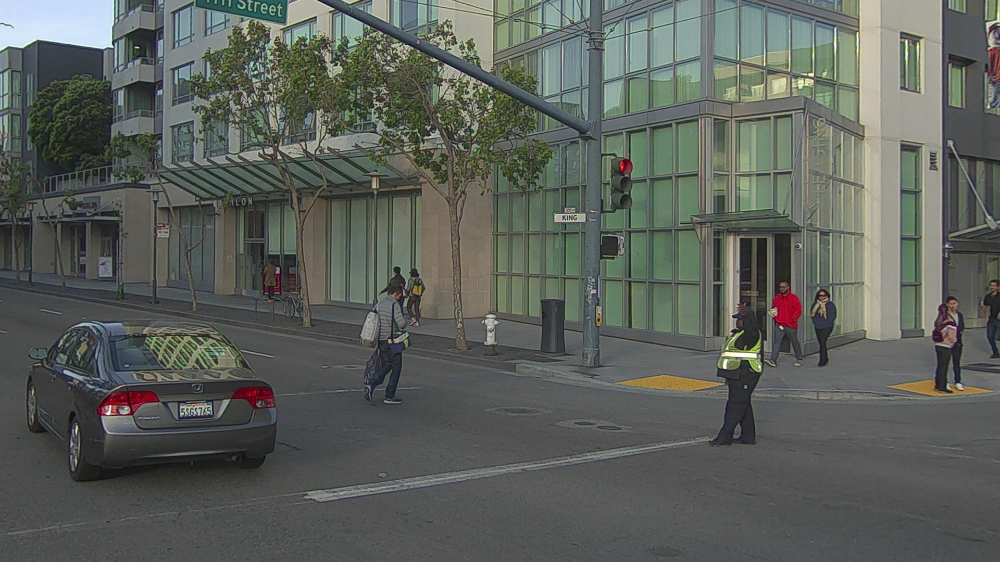

[frame 0] range_view: 1920x1080 px  -> /kaggle/working/alignment_range_view_0.png


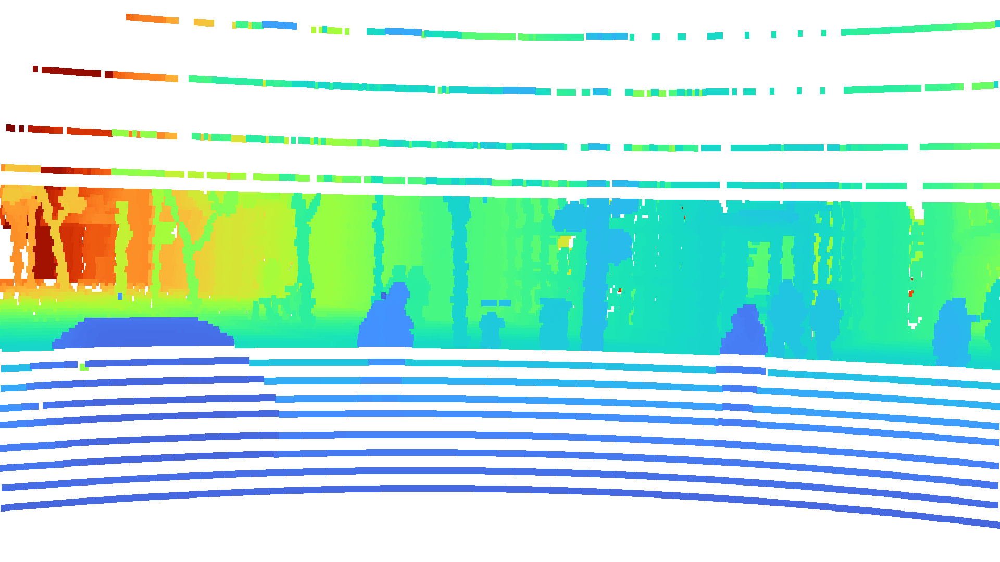

[frame 0] overlay: 1920x1080 px  -> /kaggle/working/alignment_overlay_0.png


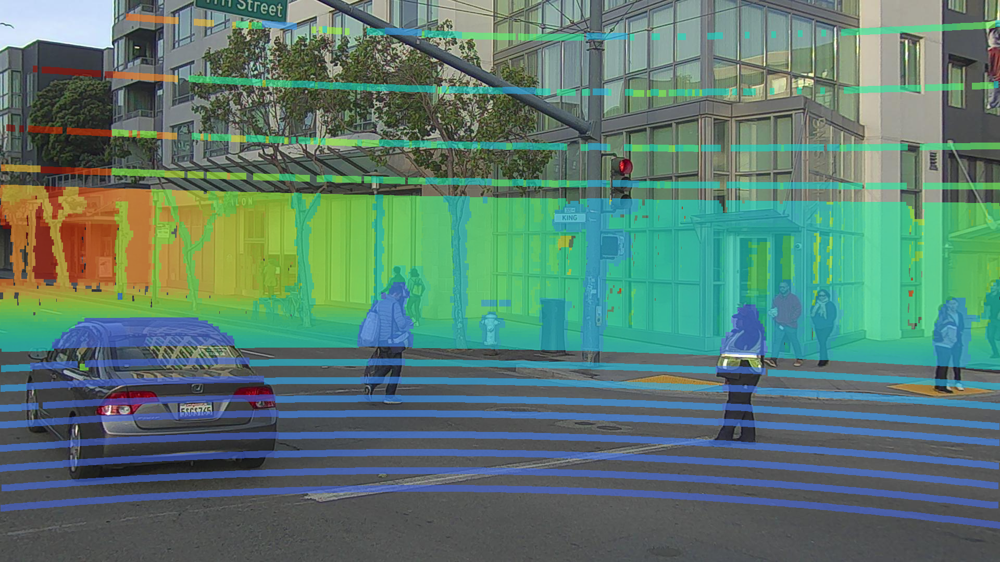

[frame 0] edge-alignment: best shift of the LiDAR = (-4 px right, +16 px down), correlation at (0,0) = 0.030, at best shift = 0.050
[frame 159] image: 1920x1080 px  -> /kaggle/working/alignment_image_159.png


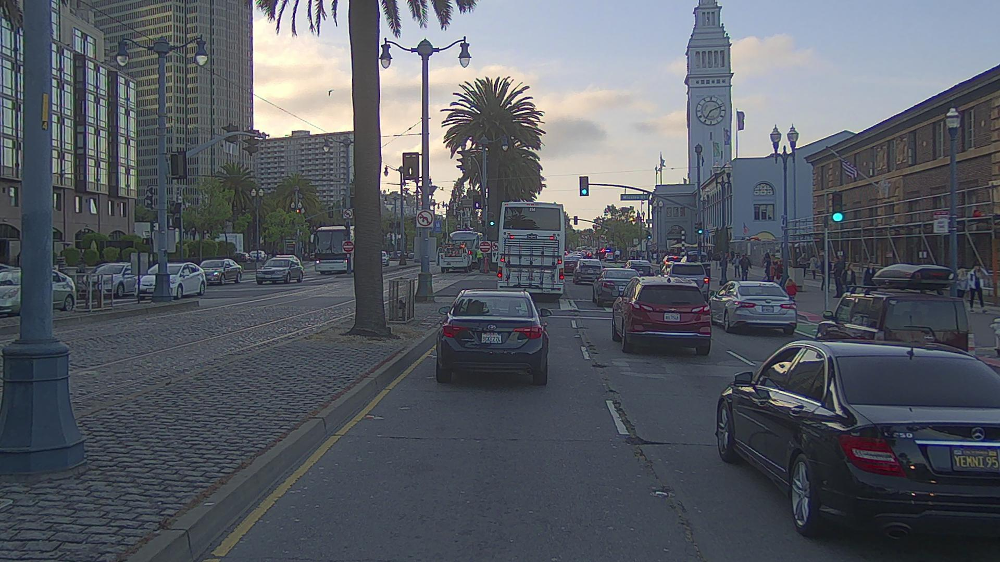

[frame 159] range_view: 1920x1080 px  -> /kaggle/working/alignment_range_view_159.png


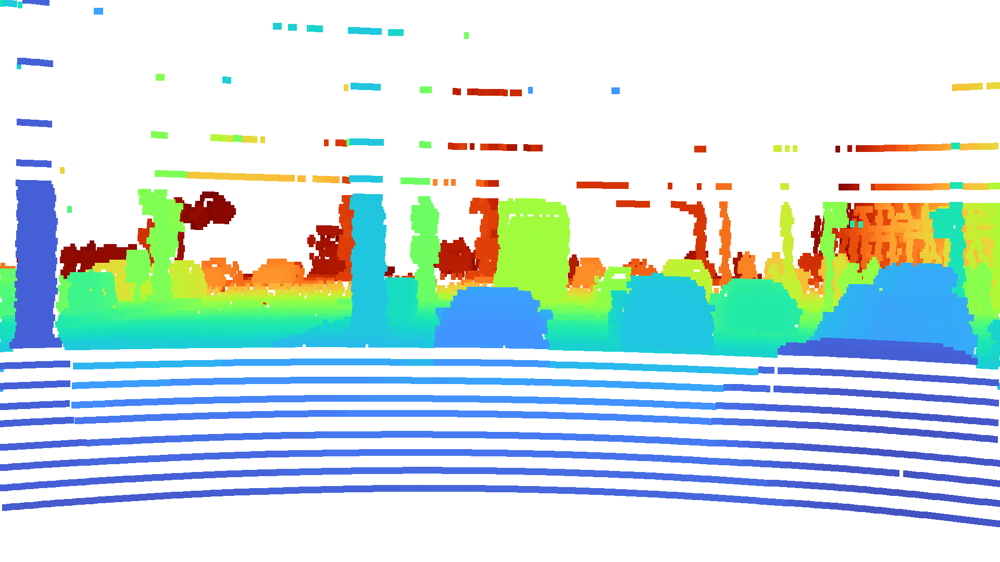

[frame 159] overlay: 1920x1080 px  -> /kaggle/working/alignment_overlay_159.png


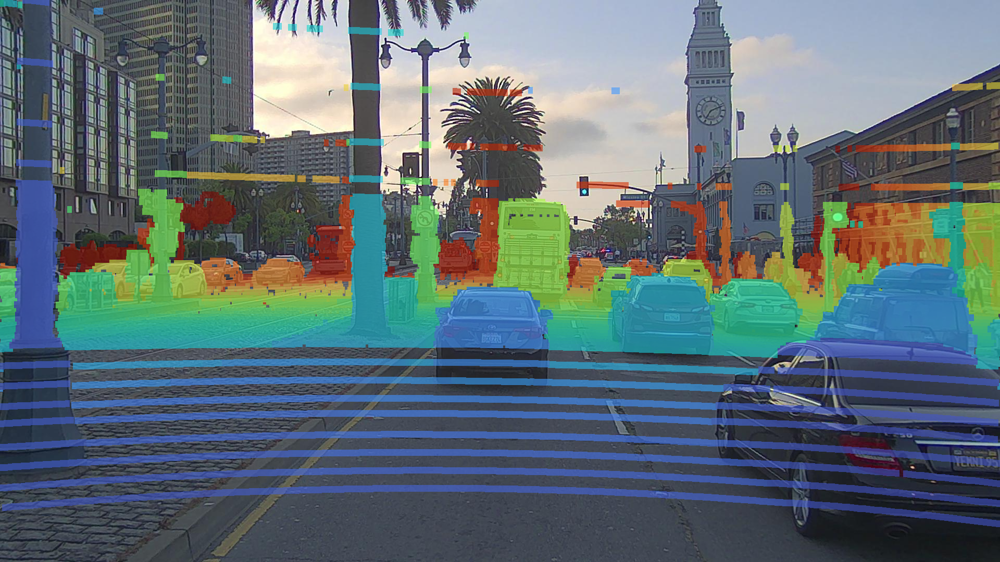

[frame 159] edge-alignment: best shift of the LiDAR = (+0 px right, +8 px down), correlation at (0,0) = 0.056, at best shift = 0.073

Mean best shift over 2 frames: (-2.0, +12.0) px  ->  possible MISALIGNMENT - check poses / intrinsics / time sync
(This is an edge-based estimate: it is reliable only in scenes with clear depth edges, e.g. cars, poles, buildings.)


In [4]:
# ============================================================================
# 1b. ALIGNMENT CHECK : 1920x1080 image  vs  1920x1080 LiDAR range view
#     (cheap, no training needed - run it first to check calibration)
# ============================================================================
def range_to_rgb(r_norm, valid):
    """Range (0..1 = 0..80 m) -> RGB uint8 image, white where there is no LiDAR."""
    rgb = (plt.get_cmap("turbo")(np.clip(r_norm, 0, 1))[..., :3] * 255).astype(np.uint8)
    rgb[~valid] = 255
    return rgb


def overlay_rgb(img_u8, range_rgb, valid, alpha=0.6):
    out = img_u8.copy().astype(np.float32)
    out[valid] = (1 - alpha) * out[valid] + alpha * range_rgb[valid].astype(np.float32)
    return out.astype(np.uint8)


def _block_mean(a, f):
    h, w = a.shape
    return a[:h // f * f, :w // f * f].reshape(h // f, f, w // f, f).mean((1, 3))


def alignment_shift_check(img_u8_hwc, rv, ds=4, max_shift=10):
    """Do depth edges of the LiDAR fall on the edges of the image?
       Correlates image-gradient magnitude with LiDAR-range-gradient magnitude for shifts of the LiDAR map.
       Returns (dx, dy) in FULL-resolution pixels = how far the LiDAR has to be moved (right, down) to match the image
       best, plus the correlation at (0,0) and at the best shift.  (0,0) means the projection is aligned."""
    g = _block_mean(img_u8_hwc.astype(np.float32).mean(2), ds)
    m = (np.asarray(rv[5], np.float32) > 0).astype(np.float32)
    r = np.asarray(rv[0], np.float32) * MAX_RANGE * m
    cnt, rs = _block_mean(m, ds), _block_mean(r, ds)
    rm = np.where(cnt > 0.5, rs / np.maximum(cnt, 1e-6), np.nan)
    gi = np.hypot(np.diff(g, axis=1)[:-1, :], np.diff(g, axis=0)[:, :-1])
    gr = np.hypot(np.diff(rm, axis=1)[:-1, :], np.diff(rm, axis=0)[:, :-1])
    gr = np.minimum(np.nan_to_num(gr, nan=0.0), 20.0)
    h, w = gi.shape

    def ncc(a, b):
        a, b = a - a.mean(), b - b.mean()
        return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-9))

    S = max_shift
    score = np.zeros((2 * S + 1, 2 * S + 1))
    for dy in range(-S, S + 1):
        for dx in range(-S, S + 1):
            ya0, ya1, yb0, yb1 = max(0, dy), h + min(0, dy), max(0, -dy), h + min(0, -dy)
            xa0, xa1, xb0, xb1 = max(0, dx), w + min(0, dx), max(0, -dx), w + min(0, -dx)
            score[dy + S, dx + S] = ncc(gi[ya0:ya1, xa0:xa1], gr[yb0:yb1, xb0:xb1])
    by, bx = np.unravel_index(np.argmax(score), score.shape)
    return (bx - S) * ds, (by - S) * ds, score[S, S], score[by, bx]


def run_alignment_check(ds, n=2):
    idxs = np.unique(np.linspace(0, len(ds) - 1, n).astype(int))
    shifts = []
    for i in idxs:
        s = ds.samples[i]
        img = load_image_np(s["img"])
        rv = lidar_to_range_image(s["lid"], s["w2c"], s["K"]).astype(np.float32)
        valid = rv[5] > 0
        rgb = range_to_rgb(rv[0], valid)
        ov = overlay_rgb(img, rgb, valid)
        for name, arr in (("image", img), ("range_view", rgb), ("overlay", ov)):
            path = os.path.join(OUT_DIR, f"alignment_{name}_{i}.png")
            Image.fromarray(arr).save(path)                    # exactly IMG_W x IMG_H pixels
            print(f"[frame {i}] {name}: {arr.shape[1]}x{arr.shape[0]} px  -> {path}")
            display(Image.fromarray(arr))
        dx, dy, s0, sb = alignment_shift_check(img, rv)
        shifts.append((dx, dy))
        print(f"[frame {i}] edge-alignment: best shift of the LiDAR = ({dx:+d} px right, {dy:+d} px down), "
              f"correlation at (0,0) = {s0:.3f}, at best shift = {sb:.3f}")
    mdx, mdy = np.mean([s[0] for s in shifts]), np.mean([s[1] for s in shifts])
    verdict = "ALIGNED (within about +-4 px)" if abs(mdx) <= 4 and abs(mdy) <= 4 else "possible MISALIGNMENT - check poses / intrinsics / time sync"
    print(f"\nMean best shift over {len(shifts)} frames: ({mdx:+.1f}, {mdy:+.1f}) px  ->  {verdict}")
    print("(This is an edge-based estimate: it is reliable only in scenes with clear depth edges, e.g. cars, poles, buildings.)")


run_alignment_check(val_ds, n=2)


In [5]:
# ============================================================================
# 2. MODEL
# ============================================================================
def cbr(i, o, s=(1, 1)):
    """Conv3x3 -> BatchNorm -> ReLU"""
    return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class PixelShuffle2d(nn.Module):
    """Depth -> space:  (B, C*rh*rw, H, W)  ->  (B, C, H*rh, W*rw)   (rh, rw may differ; rh == rw is nn.PixelShuffle)"""
    def __init__(self, rh, rw):
        super().__init__()
        self.rh, self.rw = rh, rw

    def forward(self, x):
        B, C_in, H, W = x.shape
        rh, rw = self.rh, self.rw
        C = C_in // (rh * rw)
        x = x.reshape(B, C, rh, rw, H, W).permute(0, 1, 4, 2, 5, 3)
        return x.reshape(B, C, H * rh, W * rw)


class PixelUnshuffle2d(nn.Module):
    """Space -> depth (exact inverse of PixelShuffle2d)."""
    def __init__(self, rh, rw):
        super().__init__()
        self.rh, self.rw = rh, rw

    def forward(self, x):
        B, C, Hb, Wb = x.shape
        rh, rw = self.rh, self.rw
        H, W = Hb // rh, Wb // rw
        x = x.reshape(B, C, H, rh, W, rw).permute(0, 1, 3, 5, 2, 4)
        return x.reshape(B, C * rh * rw, H, W)


def icnr_(conv, rh, rw):
    """ICNR init: PixelShuffle starts like nearest-neighbour upsampling (no checkerboard)."""
    out_ch, in_ch, kh, kw = conv.weight.shape
    base = torch.empty(out_ch // (rh * rw), in_ch, kh, kw)
    nn.init.kaiming_normal_(base)
    conv.weight.data.copy_(base.repeat_interleave(rh * rw, dim=0))


class ResBlock(nn.Module):
    """x + (Conv-BN-ReLU-Conv-BN)(x), then ReLU."""
    def __init__(self, ch):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(ch, ch, 3, 1, 1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
                                  nn.Conv2d(ch, ch, 3, 1, 1, bias=False), nn.BatchNorm2d(ch))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(x + self.body(x))


class DownBlock(nn.Module):
    """Smaller map by `stride`.  mode="conv": strided conv.  mode="unshuffle": PixelUnshuffle + conv."""
    def __init__(self, in_ch, out_ch, stride, mode="conv"):
        super().__init__()
        sh, sw = stride
        if mode == "unshuffle" and (sh, sw) != (1, 1):
            self.body = nn.Sequential(PixelUnshuffle2d(sh, sw), cbr(in_ch * sh * sw, out_ch))
        else:
            self.body = cbr(in_ch, out_ch, stride)

    def forward(self, x):
        return self.body(x)


class Encoder(nn.Module):
    """stem (4x4 patchify, stride 4)  ->  N_DOWN x [DownBlock stride 2 + ResBlock]  ->  ResBlock  ->  conv to LATENT_C.
       STRIDE 16 : 1088x1920 -> 272x480 -> 136x240 -> 68x120   |   STRIDE 32 : ... -> 34x60"""
    def __init__(self, in_ch, down="conv"):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_ch, 32, 4, 4, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        chs = [32, 64, 128, 128, 128][:N_DOWN + 1]
        layers = []
        for i in range(N_DOWN):
            layers += [DownBlock(chs[i], chs[i + 1], (2, 2), down), ResBlock(chs[i + 1])]
        layers += [ResBlock(chs[-1]), cbr(chs[-1], LATENT_C)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(self.stem(x))


class UpBlock(nn.Module):
    """Bigger map by `scale` = (rh, rw):  Conv3x3 to out_ch*rh*rw channels -> PixelShuffle2d -> BN -> ReLU."""
    def __init__(self, in_ch, out_ch, scale):
        super().__init__()
        rh, rw = scale
        self.conv = nn.Conv2d(in_ch, out_ch * rh * rw, 3, 1, 1, bias=False)
        icnr_(self.conv, rh, rw)
        self.shuffle = PixelShuffle2d(rh, rw)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.bn(self.shuffle(self.conv(x))))


class Decoder(nn.Module):
    """N_UP x [UpBlock x2 (PixelShuffle) + ResBlock]  latent -> full resolution, then a 3x3 conv to out_ch.
       STRIDE 16: channels 192-128-64-32 (v4 had 128-128-64-32-16, i.e. only 16 channels at full resolution)."""
    def __init__(self, out_ch):
        super().__init__()
        chs = {4: [LATENT_C, 192, 128, 64, 32], 5: [LATENT_C, 128, 128, 64, 32, 16]}[N_UP]
        layers = []
        for i in range(N_UP):
            layers.append(UpBlock(chs[i], chs[i + 1], (2, 2)))
            if i < N_UP - 1:
                layers.append(ResBlock(chs[i + 1]))
        layers.append(nn.Conv2d(chs[-1], out_ch, 3, 1, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class EvidentialHead(nn.Module):
    """features -> Dirichlet params alpha = softplus(logits)+1, p = alpha/S, u = K/S"""
    def __init__(self, K=K_CLASSES):
        super().__init__()
        self.K = K
        self.net = nn.Sequential(cbr(LATENT_C, LATENT_C), nn.Conv2d(LATENT_C, K, 1))

    def forward(self, f):
        evidence = F.softplus(self.net(f).float())
        alpha = evidence + 1.0
        S = alpha.sum(1, keepdim=True)
        return alpha, alpha / S, self.K / S


class GeoSemUncertainty(nn.Module):
    """U_GS = sigmoid(w1(1-IoU) + w2 D_JS + w3 u_C + w4 u_L + b)   (w learnable)"""
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.ones(4))
        self.b = nn.Parameter(torch.tensor(-1.5))

    @staticmethod
    def js_div(p, q, eps=1e-8):
        m = 0.5 * (p + q)
        kl = lambda a, b: (a * (torch.log(a + eps) - torch.log(b + eps))).sum(1, keepdim=True)
        return (0.5 * kl(p, m) + 0.5 * kl(q, m)) / math.log(2.0)

    def forward(self, pC, pL, uC, uL):
        pC, pL, uC, uL = pC.detach(), pL.detach(), uC.detach(), uL.detach()
        occC, occL = 1 - pC[:, :1], 1 - pL[:, :1]                     # class 0 = "empty"
        iou = occC * occL / (occC + occL - occC * occL + 1e-6)
        djs = self.js_div(pC, pL)
        s = self.w[0] * (1 - iou) + self.w[1] * djs + self.w[2] * uC + self.w[3] * uL + self.b
        return torch.sigmoid(s)


class UncertaintyAwareFusion(nn.Module):
    """Confidence-weighted feature mixing + U_GS-controlled channel bandwidth mask."""
    def __init__(self):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(2 * LATENT_C, LATENT_C, 1, bias=False),
                                  nn.BatchNorm2d(LATENT_C), nn.ReLU(inplace=True),
                                  nn.Conv2d(LATENT_C, LATENT_C, 3, 1, 1))          # linear output: z can be +/-
        self.register_buffer("ch", (torch.arange(LATENT_C).float() / LATENT_C).view(1, -1, 1, 1))

    def forward(self, fC, fL, uC, uL, U):
        aC, aL = 1 - uC, 1 - uL
        norm = aC + aL + 1e-6
        fused = self.proj(torch.cat([fC * (2 * aC / norm), fL * (2 * aL / norm)], 1))
        bw = MASK_MIN + (1.0 - MASK_MIN) * U                 # more uncertain -> more channels kept (>= MASK_MIN)
        mask = torch.sigmoid(12.0 * (bw - self.ch))
        return fused * mask


class SpatialAwareCompressor(nn.Module):
    """Quantiser step depends on U_GS: high U_GS -> small step (fidelity), low U_GS -> large step (compression).
       Straight-through rounding.  `bits` is a rate proxy (bits / element), NOT a real bitstream."""
    def forward(self, z, U):
        step = Q_MIN + (Q_MAX - Q_MIN) * (1.0 - U.detach())
        q = torch.round(z / step)
        z_hat = z + (q * step - z).detach()
        bits = torch.log2(1.0 + torch.abs(z) / step)
        return z_hat, bits


class DetectionHead(nn.Module):
    """Head on the decompressed latent z_hat (+ U_GS):  latent --UpBlock xDET_UP--> 136x240 --ResBlock--> heads
       hm_logit : class heat-map (what is it)      reg : [x, y, z, distance] in the camera frame"""
    def __init__(self):
        super().__init__()
        self.up = UpBlock(LATENT_C, 96, (DET_UP, DET_UP))
        self.trunk = nn.Sequential(cbr(96 + 1, 96), ResBlock(96), cbr(96, 64))
        self.hm = nn.Conv2d(64, N_DET, 1)
        self.reg = nn.Conv2d(64, 4, 1)
        nn.init.constant_(self.hm.bias, -2.19)

    def forward(self, z, U):
        h = self.up(z)
        U_up = F.interpolate(U, size=h.shape[-2:], mode="bilinear", align_corners=False).to(h.dtype)
        h = self.trunk(torch.cat([h, U_up], 1))
        return self.hm(h), self.reg(h)


class GeoSemFSP(nn.Module):
    def __init__(self):
        super().__init__()
        self.img_enc, self.lid_enc = Encoder(3), Encoder(6)
        self.head_c, self.head_l = EvidentialHead(), EvidentialHead()
        self.unc = GeoSemUncertainty()
        self.fusion = UncertaintyAwareFusion()
        self.img_dec, self.lid_dec = Decoder(3), Decoder(2)
        self.compress = SpatialAwareCompressor()
        self.det_head = DetectionHead()

    def forward(self, img, rv):
        H = img.shape[-2]
        pad = (-H) % STRIDE                                          # 1080 -> 1088 so all strides divide exactly (crops: 0)
        if pad:
            img, rv = F.pad(img, (0, 0, 0, pad)), F.pad(rv, (0, 0, 0, pad))
        fC, fL = self.img_enc(img), self.lid_enc(rv)
        aC, pC, uC = self.head_c(fC)
        aL, pL, uL = self.head_l(fL)
        U = self.unc(pC, pL, uC, uL)
        z = self.fusion(fC, fL, uC, uL, U)
        z_hat, bits = self.compress(z.float(), U)
        img_rec = torch.sigmoid(self.img_dec(z_hat)[:, :, :H])      # crop the padding again
        lo = self.lid_dec(z_hat)[:, :, :H]
        hm_logit, reg = self.det_head(z_hat, U)
        return dict(hm_logit=hm_logit, reg=reg, img=img_rec, range=torch.sigmoid(lo[:, :1]), mask_logit=lo[:, 1:],
                    aC=aC, aL=aL, pC=pC, pL=pL, uC=uC, uL=uL, U=U, z=z, z_hat=z_hat, bits=bits, fC=fC, fL=fL)


def fwd(model, img_u8, rv16):
    """uint8 image + float16 range image (on the GPU) -> float32 outputs.  Model runs in mixed precision."""
    img = img_u8.float().div_(255.0)
    rv = rv16.float()
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        out = model(img, rv)
    return {k: v.float() for k, v in out.items()}, img, rv


In [6]:
# ============================================================================
# 3. LOSSES
# ============================================================================
def ssim(x, y, C1=0.01 ** 2, C2=0.03 ** 2):
    mx, my = F.avg_pool2d(x, 7, 1, 3), F.avg_pool2d(y, 7, 1, 3)
    sx = F.avg_pool2d(x * x, 7, 1, 3) - mx ** 2
    sy = F.avg_pool2d(y * y, 7, 1, 3) - my ** 2
    sxy = F.avg_pool2d(x * y, 7, 1, 3) - mx * my
    s = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sx + sy + C2))
    return s.mean()


def gradient_loss(pred, gt):
    dx = lambda t: t[:, :, :, 1:] - t[:, :, :, :-1]
    dy = lambda t: t[:, :, 1:, :] - t[:, :, :-1, :]
    return F.l1_loss(dx(pred), dx(gt)) + F.l1_loss(dy(pred), dy(gt))


def image_loss(pred, gt):
    """L1 + MSE (the quantity PSNR measures) + SSIM + edge loss."""
    return F.l1_loss(pred, gt) + LAM_MSE * F.mse_loss(pred, gt) + (1 - ssim(pred, gt)) + LAM_GRAD * gradient_loss(pred, gt)


def lidar_loss(out, rv):
    """Masked L1 (range) + masked edge loss + BCE + Dice (mask)."""
    r_p, r_g, m = out["range"], rv[:, 0:1], rv[:, 5:6]
    l1 = (torch.abs(r_p - r_g) * m).sum() / (m.sum() + 1e-6)
    mx, my = m[:, :, :, 1:] * m[:, :, :, :-1], m[:, :, 1:, :] * m[:, :, :-1, :]
    gx = (torch.abs((r_p[:, :, :, 1:] - r_p[:, :, :, :-1]) - (r_g[:, :, :, 1:] - r_g[:, :, :, :-1])) * mx).sum() / (mx.sum() + 1e-6)
    gy = (torch.abs((r_p[:, :, 1:, :] - r_p[:, :, :-1, :]) - (r_g[:, :, 1:, :] - r_g[:, :, :-1, :])) * my).sum() / (my.sum() + 1e-6)
    bce = F.binary_cross_entropy_with_logits(out["mask_logit"], m)
    p = torch.sigmoid(out["mask_logit"])
    dice = 1 - (2 * (p * m).sum() + 1) / (p.sum() + m.sum() + 1)
    return l1 + LIDAR_GRAD_W * (gx + gy) + bce + dice


def pseudo_classes(rv):
    """Self-supervised labels for the evidential heads on the LAT_H x LAT_W latent grid (each cell = 32x32 pixels):
       class 0 = empty, classes 1..7 = coarse range bins of the LiDAR geometry."""
    rv = F.pad(rv, (0, 0, 0, (-rv.shape[-2]) % STRIDE))
    m, r = rv[:, 5:6], rv[:, 0:1] * rv[:, 5:6]
    occ = F.avg_pool2d(m, STRIDE)
    mean_r = F.avg_pool2d(r, STRIDE) / (occ + 1e-6)
    bounds = torch.tensor([0.08, 0.15, 0.25, 0.35, 0.5, 0.7], device=rv.device)
    cls = torch.bucketize(mean_r.contiguous(), bounds) + 1
    cls = torch.where(occ < 0.05, torch.zeros_like(cls), cls)
    return cls.squeeze(1).long()


def kl_dirichlet(alpha, K=K_CLASSES):
    S = alpha.sum(1, keepdim=True)
    return (torch.lgamma(S) - math.lgamma(K) - torch.lgamma(alpha).sum(1, keepdim=True)
            + ((alpha - 1) * (torch.digamma(alpha) - torch.digamma(S))).sum(1, keepdim=True))


def evidential_loss(alpha, target, kl_w):
    y = F.one_hot(target, K_CLASSES).permute(0, 3, 1, 2).float()
    S = alpha.sum(1, keepdim=True)
    p = alpha / S
    mse = ((y - p) ** 2).sum(1) + (p * (1 - p) / (S + 1)).sum(1)
    alpha_t = y + (1 - y) * alpha
    return mse.mean() + kl_w * kl_dirichlet(alpha_t).mean()


def detection_loss(out, tgt):
    """CenterNet focal loss on the heat-map + L1 on [x,y,z,dist] at object centres."""
    pred = torch.sigmoid(out["hm_logit"]).clamp(1e-4, 1 - 1e-4)
    gt = tgt["hm"]
    pos = gt.eq(1).float()
    pos_l = (torch.log(pred) * (1 - pred) ** 2 * pos).sum()
    neg_l = (torch.log(1 - pred) * pred ** 2 * (1 - gt) ** 4 * (1 - pos)).sum()
    focal = -(pos_l + neg_l) / pos.sum().clamp(min=1.0)
    rm = tgt["rm"]
    # v5: only z and distance are regressed; x / y come from the cell position + the intrinsics (decode_objects),
    #     which is exact and does not depend on absolute position (needed for crop training)
    reg = (torch.abs(out["reg"][:, 2:] - tgt["reg"][:, 2:]) * rm).sum() / (rm.sum() * 2 + 1e-6)
    return focal + 5.0 * reg


def soft_iou(pC, pL):
    a, b = 1 - pC[:, :1], 1 - pL[:, :1]
    return a * b / (a + b - a * b + 1e-6)


def feature_consistency_loss(out):
    cos = F.cosine_similarity(out["fC"], out["fL"], dim=1, eps=1e-6).unsqueeze(1)
    w = (1 - out["U"]).detach()
    return (w * (1 - cos)).sum() / (w.sum() + 1e-6)


def geo_sem_loss(out, rv, kl_w):
    pc = pseudo_classes(rv)
    evid = evidential_loss(out["aC"], pc, kl_w) + evidential_loss(out["aL"], pc, kl_w)
    agree = (1 - soft_iou(out["pC"], out["pL"])).mean() + GeoSemUncertainty.js_div(out["pC"], out["pL"]).mean()
    return evid + 0.5 * agree


def compression_loss(out):
    w = 0.5 + out["U"].detach()
    fid = (w * (out["z"] - out["z_hat"].detach()) ** 2).mean()
    rate = out["bits"].mean()
    return fid + RATE_W * rate, rate


def total_loss(out, img, rv, tgt, kl_w):
    """L = L_det + lam1*L_feat + lam2*L_geo-sem + lam3*L_comp  (+ lam_rec*L_rec)"""
    zero = torch.zeros((), device=img.device)
    l_det = detection_loss(out, tgt) if USE_DET else zero
    l_feat = feature_consistency_loss(out)
    l_gs = geo_sem_loss(out, rv, kl_w)
    l_comp, bits = compression_loss(out)
    rec_i, rec_l = image_loss(out["img"], img), lidar_loss(out, rv)
    loss = l_det + LAM_FEAT * l_feat + LAM_GEOSEM * l_gs + LAM_COMP * l_comp + LAM_REC_IMG * rec_i + LAM_REC * rec_l
    comps = dict(det=l_det, feat=l_feat, geosem=l_gs, comp=l_comp, bits=bits, img=rec_i, lid=rec_l)
    return loss, comps


Parameters: 9.39 M
smoke test OK | loss 113.27 | 0.32 s per step (batch 4)
estimated GPU time: 1.7 min per epoch  ->  0.8 h for 30 epochs (data loading may add time)
peak GPU memory: 5.0 GB  (if you get out-of-memory: BATCH_SIZE=1 or SCALE=2)


Epoch 1/30:   0%|          | 0/310 [00:00<?, ?it/s]

val:   0%|          | 0/40 [00:00<?, ?it/s]

[Epoch 1] train 10.8014 | val 10.1910 | val PSNR 19.71 dB | val range MAE 4.74 m | ~0.86 bpp (proxy) | 216s
           val terms -> L_det 6.072 | L_feat 0.621 | L_geo-sem 3.059 | L_comp 0.0181 | est. 1.71 bits/element
           U_GS mean 0.481 | std 0.037   (std near 0 = U_GS is not adapting)


Epoch 2/30:   0%|          | 0/310 [00:00<?, ?it/s]

val:   0%|          | 0/40 [00:00<?, ?it/s]

... (83 outputs left out)

val:   0%|          | 0/40 [00:00<?, ?it/s]

[Epoch 30] train 1.7400 | val 4.0446 | val PSNR 25.28 dB | val range MAE 1.36 m | ~1.21 bpp (proxy) | 144s
           val terms -> L_det 1.637 | L_feat 0.108 | L_geo-sem 2.902 | L_comp 0.0248 | est. 2.39 bits/element
           U_GS mean 0.522 | std 0.098   (std near 0 = U_GS is not adapting)


test:   0%|          | 0/40 [00:00<?, ?it/s]


===== TEST RESULTS =====
total loss 3.6123
  L_det 1.4533 | L_feat 0.0953 | L_geo-sem 2.5942 | L_comp 0.0243
  reconstruction: image loss 0.2493 | LiDAR loss 0.0542
  transmission  : ~2.34 bits per latent element (rate proxy; float32 = 32 bits)
image PSNR 25.92 dB at ~1.18 bpp (rate proxy) | LiDAR range MAE 1.41 m
detection loss 1.453 | object distance MAE at labelled centres 3.90 m


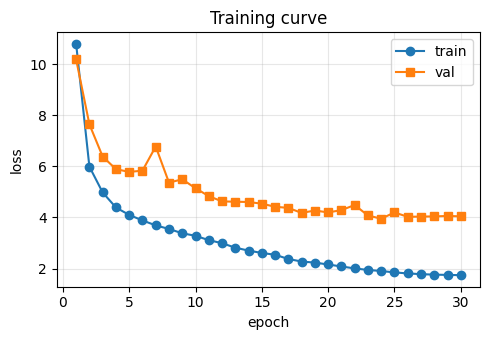


Detection precision / recall on the validation set (all classes):
  thr  precision   recall      TP      FP      FN
 0.10      0.290    0.406    2492    6109    3639
 0.15      0.418    0.382    2343    3258    3788
 0.20      0.517    0.366    2243    2099    3888
 0.30      0.649    0.334    2045    1104    4086
 0.40      0.738    0.303    1855     659    4276


In [7]:
# ============================================================================
# 4. TRAIN / EVAL
# ============================================================================
model = GeoSemFSP().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dl))
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)


def to_dev(tgt):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in tgt.items()}


def _smoke_test():
    """Runs a few full train steps on random data: checks shapes, measures GPU memory and the time per step."""
    _m = GeoSemFSP().to(DEVICE); _m.train()
    _o = torch.optim.AdamW(_m.parameters(), 1e-4); _s = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    B = BATCH_SIZE
    th, tw = (CROP_H, CROP_W) if TRAIN_CROP else (IMG_H, IMG_W)              # size of a TRAINING sample
    dh, dw = (CROP_H // DET_STRIDE, CROP_W // DET_STRIDE) if TRAIN_CROP else (DET_H, DET_W)
    _img = torch.randint(0, 255, (B, 3, th, tw), dtype=torch.uint8, device=DEVICE)
    _rv = torch.rand(B, 6, th, tw, device=DEVICE); _rv[:, 5] = (_rv[:, 5] > 0.9).float(); _rv = _rv.half()
    _t = dict(hm=torch.zeros(B, N_DET, dh, dw, device=DEVICE), reg=torch.zeros(B, 4, dh, dw, device=DEVICE),
              rm=torch.zeros(B, 1, dh, dw, device=DEVICE))
    _t["hm"][:, 0, 10, 20] = 1; _t["rm"][:, 0, 10, 20] = 1
    _x = torch.randn(2, 8, 5, 7)                                           # PixelShuffle2d must match nn.PixelShuffle and be invertible
    assert torch.equal(PixelUnshuffle2d(2, 2)(PixelShuffle2d(2, 2)(_x)), _x)
    assert torch.equal(PixelShuffle2d(2, 2)(_x), nn.PixelShuffle(2)(_x))
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    dt = 0.0
    for it in range(3):
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        out, img_f, rv_f = fwd(_m, _img, _rv)
        assert out["img"].shape == (B, 3, th, tw) and out["range"].shape == (B, 1, th, tw), out["img"].shape
        assert out["hm_logit"].shape == (B, N_DET, dh, dw) and out["z"].shape[1] == LATENT_C
        loss, c = total_loss(out, img_f, rv_f, _t, 0.05)
        _o.zero_grad(set_to_none=True); _s.scale(loss).backward(); _s.step(_o); _s.update()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0
    print(f"smoke test OK | loss {loss.item():.2f} | {dt:.2f} s per step (batch {B})")
    print(f"estimated GPU time: {dt * len(train_dl) / 60:.1f} min per epoch  ->  {dt * len(train_dl) * EPOCHS / 3600:.1f} h for {EPOCHS} epochs "
          f"(data loading may add time)")
    if DEVICE.type == "cuda":
        print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB  (if you get out-of-memory: BATCH_SIZE=1 or SCALE=2)")
    del _m, _o, out, loss
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


_smoke_test()


@torch.no_grad()
def evaluate(loader, desc="eval"):
    model.eval()
    keys = ["loss", "det", "feat", "geosem", "comp", "bits", "img", "lid", "psnr", "mae_m", "u_mean", "u_std", "bpp"]
    tot = {k: 0.0 for k in keys}; n_tot = 0
    d_sum, d_n = 0.0, 0.0
    for img_u8, rv16, tgt in tqdm(loader, desc=desc, leave=False):
        out, img, rv = fwd(model, img_u8.to(DEVICE, non_blocking=True), rv16.to(DEVICE, non_blocking=True))
        tgt = to_dev(tgt)
        loss, comps = total_loss(out, img, rv, tgt, 1.0)
        b = img.size(0)
        mse = F.mse_loss(out["img"], img)
        m = rv[:, 5:6]
        mae = (torch.abs(out["range"] - rv[:, :1]) * m).sum() / (m.sum() + 1e-6) * MAX_RANGE
        vals = dict(comps, loss=loss, psnr=10 * torch.log10(1 / (mse + 1e-8)), mae_m=mae,
                    u_mean=out["U"].mean(), u_std=out["U"].std(),
                    bpp=out["bits"].mean() * out["bits"][0].numel() / (img.shape[-2] * img.shape[-1]))   # rate PROXY, bits per image pixel
        for k in keys: tot[k] += vals[k].item() * b
        n_tot += b
        rm = tgt["rm"]
        d_sum += (torch.abs(out["reg"][:, 3:4] - tgt["reg"][:, 3:4]) * rm).sum().item() * MAX_RANGE
        d_n += rm.sum().item()
    res = {k: v / n_tot for k, v in tot.items()}
    res["det_dist_mae"] = d_sum / d_n if d_n > 0 else float("nan")
    return res


history = []
best_val, best_path = float("inf"), os.path.join(OUT_DIR, "geosem_fsp_best.pt")
step, total_steps = 0, EPOCHS * len(train_dl)

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, run = time.time(), 0.0
    pbar = tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}")
    for img_u8, rv16, tgt in pbar:
        img_u8, rv16, tgt = img_u8.to(DEVICE, non_blocking=True), rv16.to(DEVICE, non_blocking=True), to_dev(tgt)
        kl_w = KL_MAX * min(1.0, step / (0.5 * total_steps))
        out, img, rv = fwd(model, img_u8, rv16)
        loss, c = total_loss(out, img, rv, tgt, kl_w)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step(); step += 1
        run += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}", det=f"{c['det'].item():.3f}", feat=f"{c['feat'].item():.3f}",
                         gs=f"{c['geosem'].item():.3f}", comp=f"{c['comp'].item():.3f}", bits=f"{c['bits'].item():.2f}")
    val = evaluate(val_dl, "val")
    tr_loss = run / len(train_dl)
    history.append((tr_loss, val["loss"]))
    print(f"[Epoch {epoch}] train {tr_loss:.4f} | val {val['loss']:.4f} | val PSNR {val['psnr']:.2f} dB | "
          f"val range MAE {val['mae_m']:.2f} m | ~{val['bpp']:.2f} bpp (proxy) | {time.time() - t0:.0f}s")
    print(f"           val terms -> L_det {val['det']:.3f} | L_feat {val['feat']:.3f} | "
          f"L_geo-sem {val['geosem']:.3f} | L_comp {val['comp']:.4f} | est. {val['bits']:.2f} bits/element")
    print(f"           U_GS mean {val['u_mean']:.3f} | std {val['u_std']:.3f}   (std near 0 = U_GS is not adapting)")
    if val["loss"] < best_val:
        best_val = val["loss"]; torch.save(model.state_dict(), best_path)

# ---- final test with best checkpoint ----
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
test = evaluate(test_dl, "test")
print("\n===== TEST RESULTS =====")
print(f"total loss {test['loss']:.4f}")
print(f"  L_det {test['det']:.4f} | L_feat {test['feat']:.4f} | L_geo-sem {test['geosem']:.4f} | L_comp {test['comp']:.4f}")
print(f"  reconstruction: image loss {test['img']:.4f} | LiDAR loss {test['lid']:.4f}")
print(f"  transmission  : ~{test['bits']:.2f} bits per latent element (rate proxy; float32 = 32 bits)")
print(f"image PSNR {test['psnr']:.2f} dB at ~{test['bpp']:.2f} bpp (rate proxy) | LiDAR range MAE {test['mae_m']:.2f} m")
if USE_DET:
    print(f"detection loss {test['det']:.3f} | object distance MAE at labelled centres {test['det_dist_mae']:.2f} m")

plt.figure(figsize=(5, 3.5))
plt.plot(range(1, EPOCHS + 1), [h[0] for h in history], "o-", label="train")
plt.plot(range(1, EPOCHS + 1), [h[1] for h in history], "s-", label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.title("Training curve")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150); plt.show()



# ---- detection precision / recall on the validation set (choose the thresholds with this, not by eye) ----
@torch.no_grad()
def detection_pr(loader, thrs=(0.10, 0.15, 0.20, 0.30, 0.40), max_batches=40, tol=2):
    """A prediction is a TRUE POSITIVE if a ground-truth centre of the same class lies within `tol` heat-map cells
       (= tol*8 px) and is not already matched.  Ground truth = every labelled cuboid centre inside the image
       (up to 80 m), including objects that are occluded or have no LiDAR points, so recall < 100 % is expected."""
    model.eval()
    stat = {t: dict(tp=0, fp=0, fn=0) for t in thrs}
    for bi, (img_u8, rv16, tgt) in enumerate(loader):
        if bi >= max_batches: break
        out, _, _ = fwd(model, img_u8.to(DEVICE), rv16.to(DEVICE))
        hm = torch.sigmoid(out["hm_logit"])
        keep = (F.max_pool2d(hm, 3, 1, 1) == hm).float() * hm
        for b in range(hm.shape[0]):
            for c in range(N_DET):
                gy, gx = torch.nonzero(tgt["hm"][b, c].eq(1), as_tuple=True)
                gt = list(zip(gy.tolist(), gx.tolist()))
                sc = keep[b, c].flatten()
                s_sorted, idx = sc.sort(descending=True)
                for t in thrs:
                    used, tp, fp = set(), 0, 0
                    for s_, ind in zip(s_sorted.tolist(), idx.tolist()):
                        if s_ < t: break
                        y, x = divmod(ind, hm.shape[-1])
                        hit = next((j for j, (a, bb) in enumerate(gt) if j not in used and abs(a - y) <= tol and abs(bb - x) <= tol), None)
                        if hit is None: fp += 1
                        else: used.add(hit); tp += 1
                    stat[t]["tp"] += tp; stat[t]["fp"] += fp; stat[t]["fn"] += len(gt) - tp
    print(f"{'thr':>5} {'precision':>10} {'recall':>8} {'TP':>7} {'FP':>7} {'FN':>7}")
    for t in thrs:
        s_ = stat[t]; p = s_["tp"] / max(1, s_["tp"] + s_["fp"]); r = s_["tp"] / max(1, s_["tp"] + s_["fn"])
        print(f"{t:>5.2f} {p:>10.3f} {r:>8.3f} {s_['tp']:>7d} {s_['fp']:>7d} {s_['fn']:>7d}")
    return stat


if USE_DET:
    print("\nDetection precision / recall on the validation set (all classes):")
    detection_pr(val_dl)



===== test frame 98 | image PSNR 25.9 dB =====
image_input: 1920x1080 px -> /kaggle/working/image_input_98.png


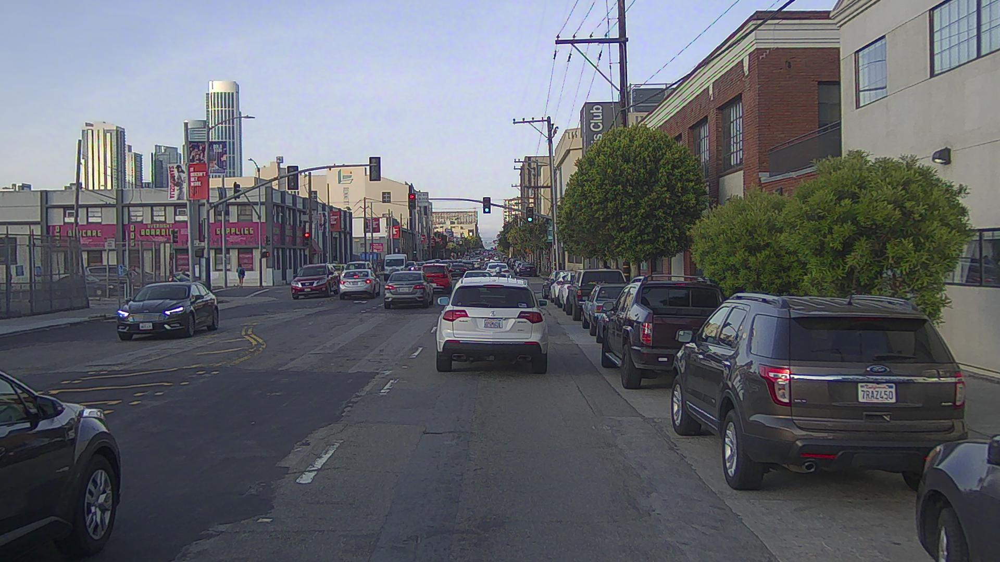

image_reconstructed: 1920x1080 px -> /kaggle/working/image_reconstructed_98.png


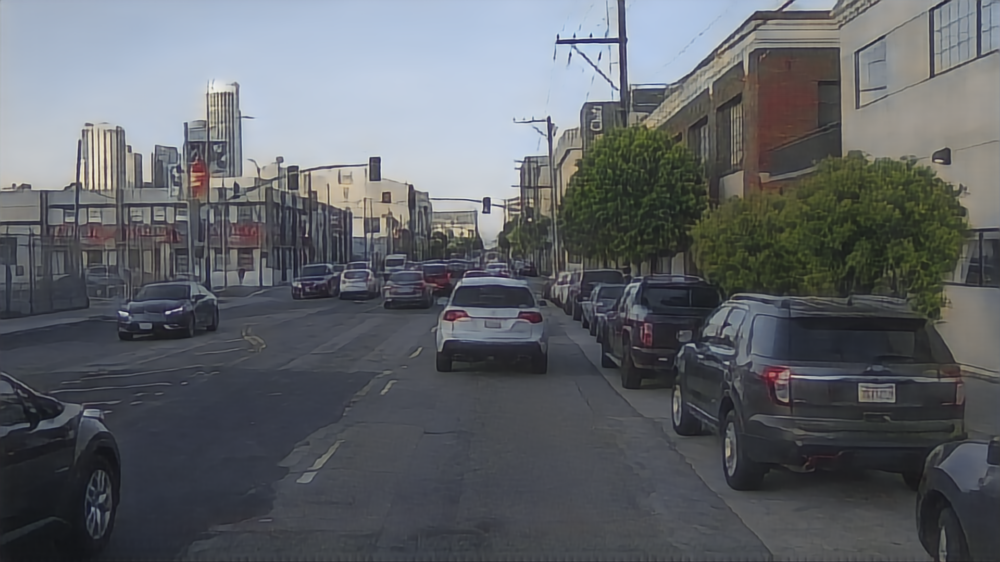

range_view_input: 1920x1080 px -> /kaggle/working/range_view_input_98.png


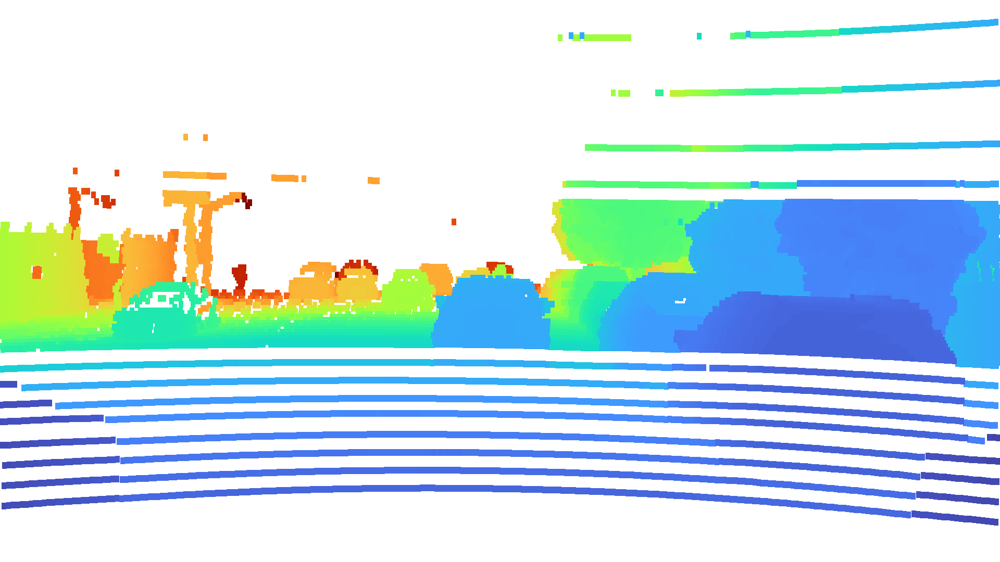

range_view_reconstructed: 1920x1080 px -> /kaggle/working/range_view_reconstructed_98.png


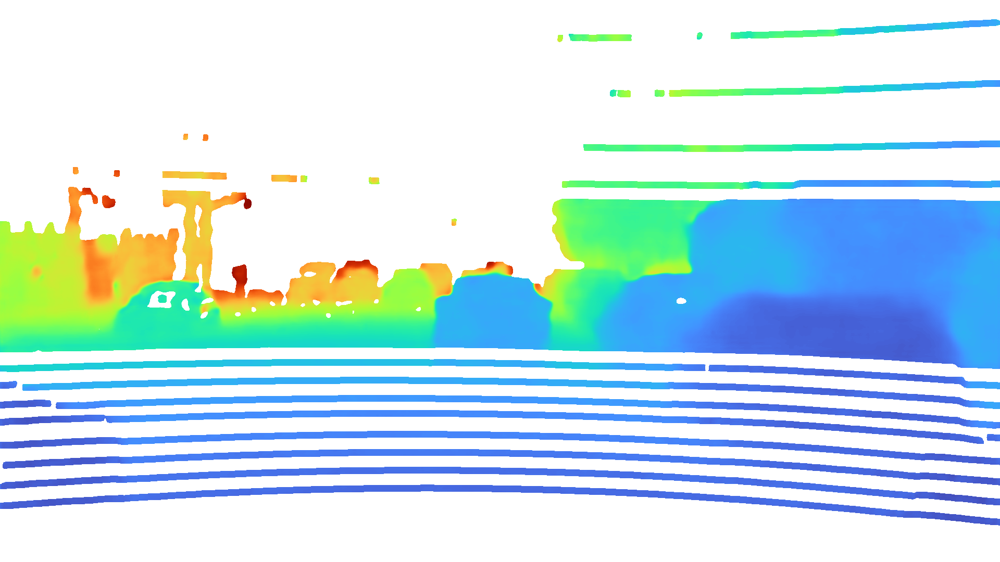

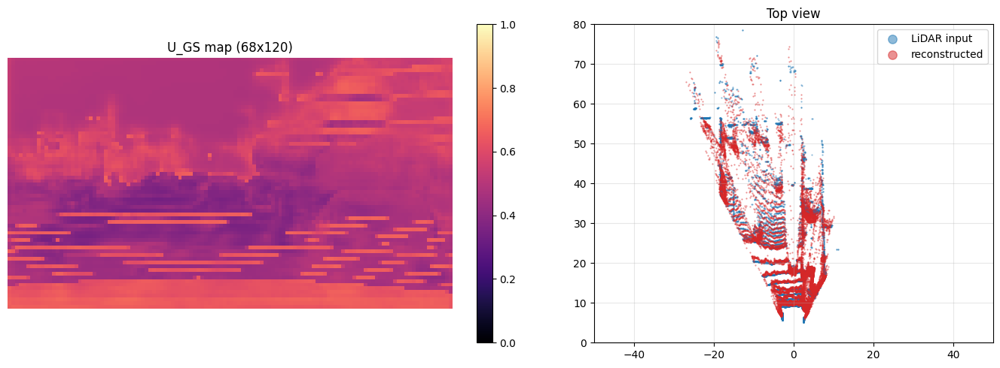


===== test frame 107 | image PSNR 25.5 dB =====
image_input: 1920x1080 px -> /kaggle/working/image_input_107.png


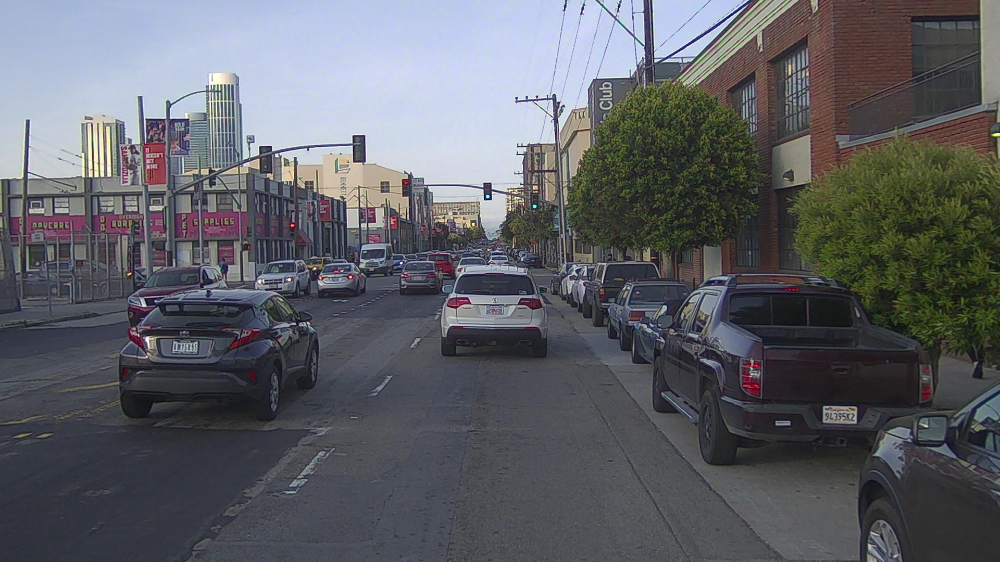

image_reconstructed: 1920x1080 px -> /kaggle/working/image_reconstructed_107.png


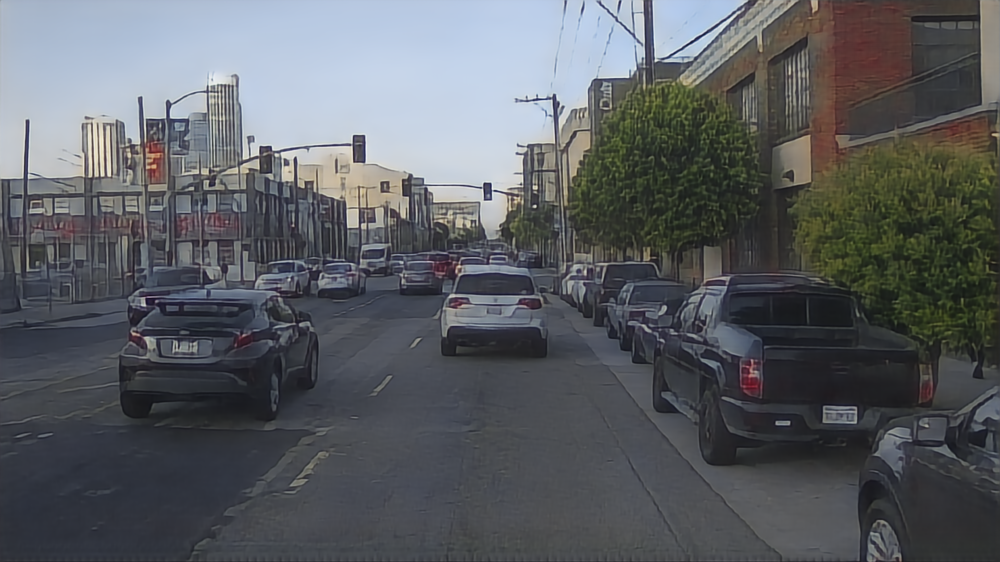

range_view_input: 1920x1080 px -> /kaggle/working/range_view_input_107.png


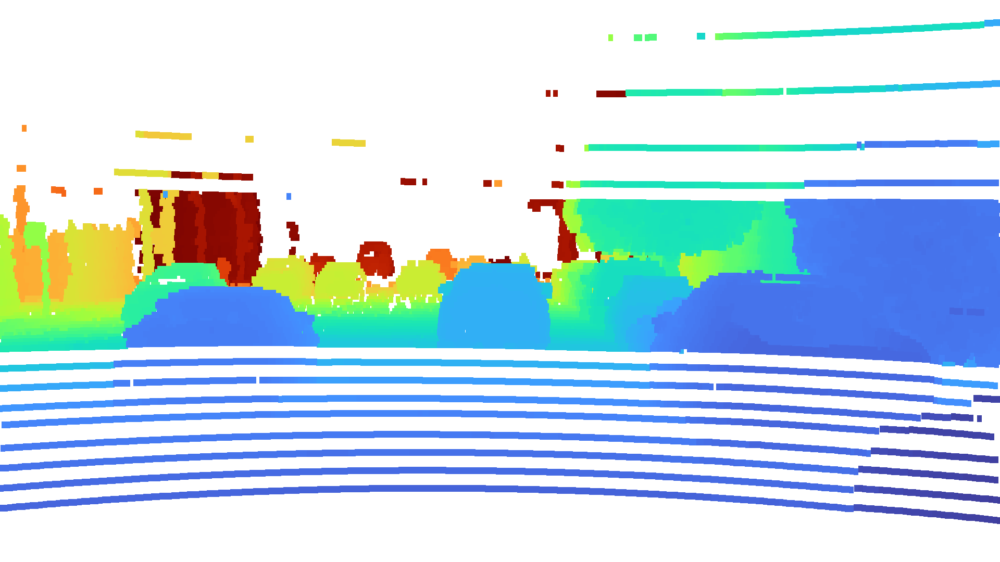

range_view_reconstructed: 1920x1080 px -> /kaggle/working/range_view_reconstructed_107.png


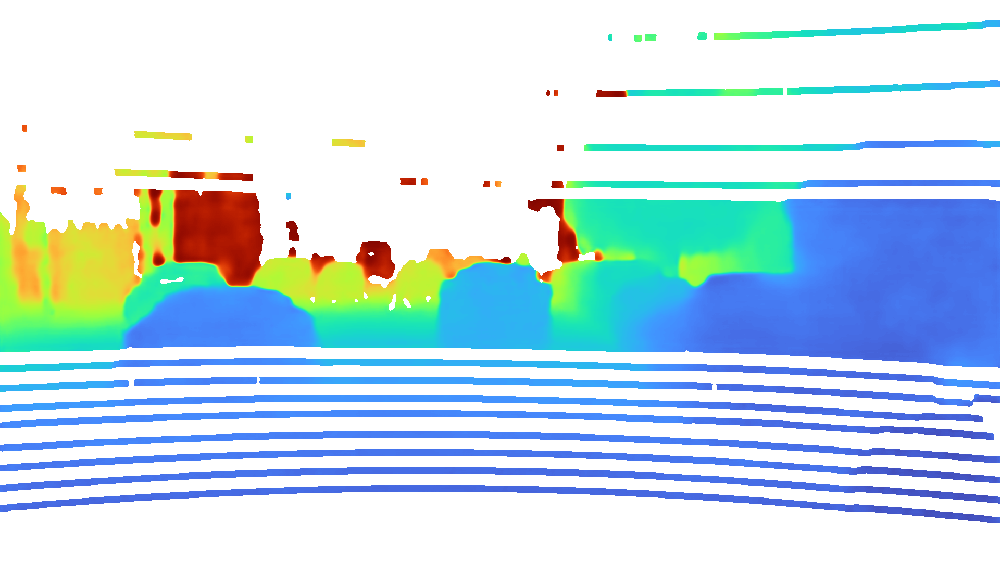

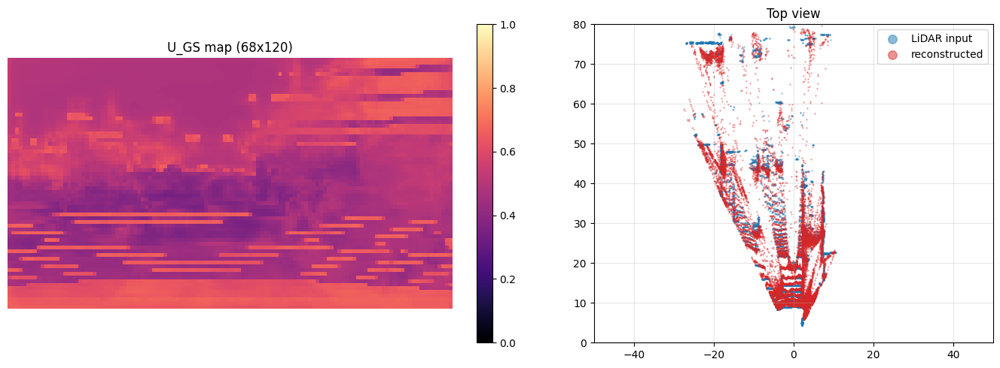

In [8]:
# ============================================================================
# 5. SHOW RECONSTRUCTED IMAGE + LiDAR at 1920x1080  (test set)
# ============================================================================
@torch.no_grad()
def show_results(ds, n=2, seed=0):
    model.eval()
    idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    for i in idxs:
        img_t, rv_t, _ = ds[i]
        out, _, _ = fwd(model, img_t[None].to(DEVICE), rv_t[None].to(DEVICE))
        gt_img = img_t.permute(1, 2, 0).numpy()
        rec_img = (out["img"][0].clamp(0, 1).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
        gt_valid, gt_rng = rv_t[5].float().numpy() > 0, rv_t[0].float().numpy()
        pm = torch.sigmoid(out["mask_logit"])[0, 0].cpu().numpy() > 0.5
        rec_rng = out["range"][0, 0].cpu().numpy()
        psnr = 10 * np.log10(255.0 ** 2 / (np.mean((rec_img.astype(np.float32) - gt_img.astype(np.float32)) ** 2) + 1e-8))
        four = [("image_input", gt_img), ("image_reconstructed", rec_img),
                ("range_view_input", range_to_rgb(gt_rng, gt_valid)), ("range_view_reconstructed", range_to_rgb(rec_rng, pm))]
        print(f"\n===== test frame {i} | image PSNR {psnr:.1f} dB =====")
        for name, arr in four:
            path = os.path.join(OUT_DIR, f"{name}_{i}.png")
            Image.fromarray(arr).save(path)
            print(f"{name}: {arr.shape[1]}x{arr.shape[0]} px -> {path}")
            display(Image.fromarray(arr))

        # U_GS map + top view of the rebuilt point cloud (rays from the intrinsics)
        fig, axs = plt.subplots(1, 2, figsize=(14, 5))
        im = axs[0].imshow(out["U"][0, 0].cpu().numpy(), cmap="magma", vmin=0, vmax=1)
        axs[0].set_title(f"U_GS map ({LAT_H}x{LAT_W})"); axs[0].axis("off"); plt.colorbar(im, ax=axs[0], fraction=0.046)
        fx, fy, cx0, cy0 = ds.samples[i]["K"]
        uu = ((np.arange(IMG_W) + 0.5) * ORIG_W / IMG_W - cx0) / fx
        vv = ((np.arange(IMG_H) + 0.5) * ORIG_H / IMG_H - cy0) / fy
        for rmap, valid, col, name in ((gt_rng, gt_valid, "tab:blue", "LiDAR input"), (rec_rng, pm, "tab:red", "reconstructed")):
            ys, xs = np.nonzero(valid[::6, ::6]); ys, xs = ys * 6, xs * 6
            r = rmap[ys, xs] * MAX_RANGE; a, b = uu[xs], vv[ys]; nrm = np.sqrt(a * a + b * b + 1.0)
            axs[1].scatter(r * a / nrm, r / nrm, s=0.3, c=col, alpha=0.5, label=name)
        axs[1].set_aspect("equal"); axs[1].set_xlim(-50, 50); axs[1].set_ylim(0, 80)
        axs[1].set_title("Top view"); axs[1].legend(markerscale=15); axs[1].grid(alpha=.3)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"topview_{i}.png"), dpi=130); plt.show()


show_results(test_ds, n=2)



SCENE REPORT  (test frame 145)   |   reconstructed image PSNR 24.80 dB
Detected objects : 8 Car, 11 Pedestrian
Ground-truth     : 9 Car, 21 Pedestrian
Total detected   : 19
 # class        conf  dist(final)  dist(pred)  dist(LiDAR)  lateral  direction reliab.
 1 Car          0.95       12.6 m      14.0 m       12.6 m   +2.6 m  right      0.62
 2 Pedestrian   0.80       38.3 m      37.6 m       38.3 m   +8.3 m  right      0.48
 3 Pedestrian   0.83       38.5 m      39.5 m       38.5 m   +9.5 m  right      0.49
 4 Pedestrian   0.84       38.7 m      39.5 m       38.7 m  +10.3 m  right      0.56
 5 Car          0.93       41.5 m      43.6 m       41.5 m   +2.7 m  ahead      0.61
 6 Car          0.95       46.2 m      47.3 m       46.2 m   -0.5 m  ahead      0.62
 7 Pedestrian   0.43       48.0 m      73.0 m       48.0 m  +10.3 m  right      0.50
 8 Car          0.48       52.9 m      57.1 m       52.9 m  +26.8 m  right      0.49
 9 Pedestrian   0.85       55.4 m      57.4 m       55.4 m 

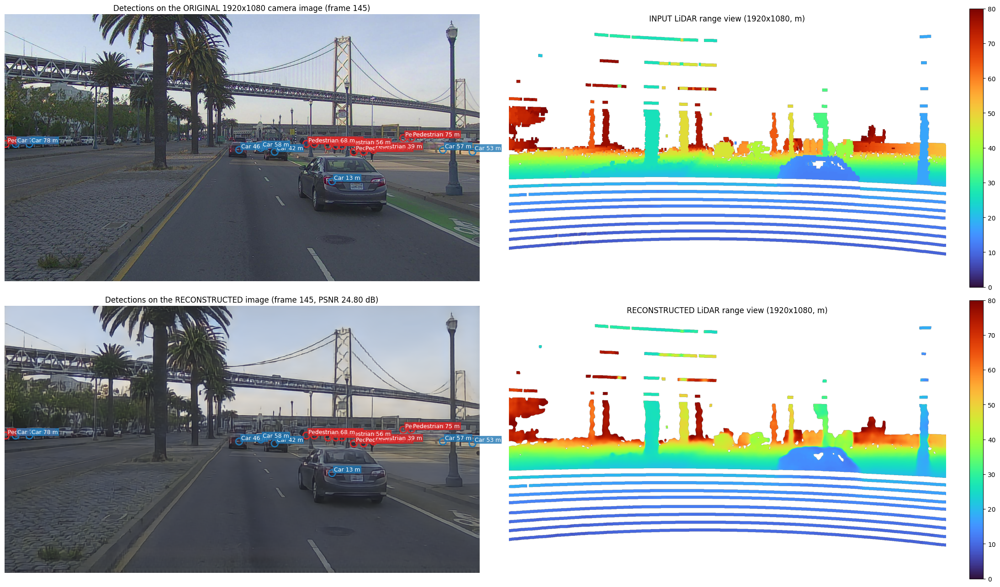


Saved scene_reports.json and scene_report_*.png in /kaggle/working


In [9]:
# ============================================================================
# 6. SCENE REPORT AFTER FUSION : what objects, how many, how far
# ============================================================================
def zone_distances(rec_range_m, rec_mask, K):
    """Nearest reconstructed LiDAR return in left / centre / right third of the image, in a band around the
       horizon (-4..+8 deg elevation, found with the intrinsics) to mostly skip the road."""
    fx, fy, cx, cy = K
    v_hi = cy - fy * math.tan(math.radians(8.0))
    v_lo = cy - fy * math.tan(math.radians(-4.0))
    r0 = int(np.clip(v_hi / ORIG_H * IMG_H, 0, IMG_H - 2))
    r1 = int(np.clip(v_lo / ORIG_H * IMG_H, r0 + 1, IMG_H))
    out = {}
    for name, (c0, c1) in dict(left=(0, IMG_W // 3), centre=(IMG_W // 3, 2 * IMG_W // 3), right=(2 * IMG_W // 3, IMG_W)).items():
        band = rec_range_m[r0:r1, c0:c1]; ok = rec_mask[r0:r1, c0:c1] > 0
        out[name] = float(band[ok].min()) if ok.sum() > 20 else None
    return out


@torch.no_grad()
def decode_objects(out, rv_t, K, thr=DET_THR, topk=DET_TOPK):
    """Heat-map peaks -> objects (ONE class per location, per-class thresholds).
       dist_pred_m : distance regressed by the network (from the compressed latent only)
       dist_lidar_m: nearest LiDAR surface around the cell (vehicle-side measurement)
       dist_m      : distance used in the report = LiDAR value if available, else the prediction
       u_px, v_px  : centre of the heat-map cell in NATIVE image pixels (where the network localised the object)
       v5: lateral x / height y are computed from the cell position, the regressed depth z and the intrinsics K:
           x = (u-cx)/fx * z ,  y = (v-cy)/fy * z   (azimuth = atan((u-cx)/fx))"""
    hm = torch.sigmoid(out["hm_logit"][0])
    score_map, cls_map = hm.max(0)
    keep = (F.max_pool2d(score_map[None, None], 3, 1, 1)[0, 0] == score_map).float()
    scores, inds = (keep * score_map).flatten().topk(min(topk, score_map.numel()))
    cls_flat = cls_map.flatten()
    rv = rv_t.float().numpy()
    fx, fy, cx0, cy0 = K
    objs = []
    for s_, ind in zip(scores.tolist(), inds.tolist()):
        if s_ < thr: break
        c = int(cls_flat[ind]); y, x = divmod(ind, DET_W)
        if s_ < DET_THR_CLS[DET_CLASSES[c]]: continue
        r = out["reg"][0, :, y, x].cpu().numpy()
        Z, D = float(r[2] * 80), float(r[3] * 80)
        u_px = (x + 0.5) * DET_STRIDE * ORIG_W / IMG_W
        v_px = (y + 0.5) * DET_STRIDE * ORIG_H / IMG_H
        X, Y = (u_px - cx0) / fx * Z, (v_px - cy0) / fy * Z
        az = math.degrees(math.atan2(u_px - cx0, fx))
        cs = DET_STRIDE
        r0, r1, c0, c1 = max(0, (y - 1) * cs), min(IMG_H, (y + 2) * cs), max(0, (x - 1) * cs), min(IMG_W, (x + 2) * cs)
        vals = rv[0, r0:r1, c0:c1][rv[5, r0:r1, c0:c1] > 0]
        lid_d = float(np.percentile(vals, 25) * MAX_RANGE) if vals.size >= 5 else None
        unc = float(out["U"][0, 0, min(y // DET_UP, out["U"].shape[2] - 1), min(x // DET_UP, out["U"].shape[3] - 1)])
        objs.append(dict(cls=DET_CLASSES[c], score=round(s_, 3), x_m=round(X, 1), y_m=round(Y, 1), z_m=round(Z, 1),
                         dist_pred_m=round(D, 1), dist_lidar_m=None if lid_d is None else round(lid_d, 1),
                         dist_m=round(lid_d if lid_d is not None else D, 1), azimuth_deg=round(az, 1),
                         direction="left" if az < -8 else "right" if az > 8 else "ahead", reliability=round(1 - unc, 2),
                         u_px=round(u_px), v_px=round(v_px)))
    return sorted(objs, key=lambda o: o["dist_m"])


def _draw_markers(ax, objs, cmap):
    for o in objs:
        u, v = o["u_px"] * IMG_W / ORIG_W, o["v_px"] * IMG_H / ORIG_H
        col = cmap(DET_CLASSES.index(o["cls"]))
        ax.scatter([u], [v], s=110, facecolors="none", edgecolors=col, linewidths=2)
        ax.text(u + 8, v - 8, f"{o['cls']} {o['dist_m']:.0f} m", color="white", fontsize=9,
                bbox=dict(facecolor=col, alpha=0.8, pad=1.5, edgecolor="none"))


@torch.no_grad()
def scene_report(ds, n=3, seed=1, frames=None):
    """frames=[145] -> report exactly these test-set frame indices (otherwise n random ones, as in v4).
       Figure per frame (2 x 2):   row 1 = ORIGINAL image + detections | INPUT LiDAR range view
                                   row 2 = RECONSTRUCTED image + the same detections | RECONSTRUCTED LiDAR range view"""
    model.eval()
    if frames is None:
        idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    else:
        idxs = [i for i in frames if 0 <= i < len(ds)]
        for i in frames:
            if i not in idxs: print(f"[skip] frame {i}: the test set only has {len(ds)} frames (indices 0..{len(ds) - 1})")
    all_reports = []
    cmap = plt.get_cmap("tab10")
    for i in idxs:
        img_t, rv_t, tgt = ds[i]
        out, _, _ = fwd(model, img_t[None].to(DEVICE), rv_t[None].to(DEVICE))
        pm = torch.sigmoid(out["mask_logit"])[0, 0].cpu().numpy() > 0.5
        rec_r = out["range"][0, 0].cpu().numpy() * MAX_RANGE
        rec_img = (out["img"][0].clamp(0, 1).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
        gt_img = img_t.permute(1, 2, 0).numpy()
        psnr = 10 * np.log10(255.0 ** 2 / (np.mean((rec_img.astype(np.float32) - gt_img.astype(np.float32)) ** 2) + 1e-8))
        gt_valid, gt_r = rv_t[5].float().numpy() > 0, rv_t[0].float().numpy() * MAX_RANGE
        zones = zone_distances(rec_r, pm.astype(np.float32), ds.samples[i]["K"])
        objs = decode_objects(out, rv_t, ds.samples[i]["K"]) if USE_DET else []
        gt_cnt = {DET_CLASSES[c]: int(tgt["hm"][c].eq(1).sum()) for c in range(N_DET)} if USE_DET else {}
        counts = {}
        for o in objs: counts[o["cls"]] = counts.get(o["cls"], 0) + 1
        print("\n" + "=" * 90)
        print(f"SCENE REPORT  (test frame {i})   |   reconstructed image PSNR {psnr:.2f} dB")
        if USE_DET:
            print("Detected objects :", ", ".join(f"{v} {k}" for k, v in counts.items()) or "none above threshold")
            print("Ground-truth     :", ", ".join(f"{v} {k}" for k, v in gt_cnt.items() if v) or "none")
            print(f"Total detected   : {len(objs)}")
            if objs:
                print(f"{'#':>2} {'class':<11}{'conf':>6}{'dist(final)':>13}{'dist(pred)':>12}{'dist(LiDAR)':>13}{'lateral':>9}  {'direction':<7}{'reliab.':>8}")
                for k, o in enumerate(objs, 1):
                    ld_ = "-" if o["dist_lidar_m"] is None else f"{o['dist_lidar_m']:.1f} m"
                    print(f"{k:>2} {o['cls']:<11}{o['score']:>6.2f}{o['dist_m']:>11.1f} m{o['dist_pred_m']:>10.1f} m{ld_:>13}"
                          f"{o['x_m']:>+7.1f} m  {o['direction']:<7}{o['reliability']:>8.2f}")
                print("   dist(final) = LiDAR distance when available, otherwise the network prediction")
        fmt = lambda v: "no return" if v is None else f"{v:.1f} m"
        print(f"Nearest LiDAR return  left: {fmt(zones['left'])} | centre: {fmt(zones['centre'])} | right: {fmt(zones['right'])}")
        if USE_DET and objs:
            print(f"Closest object: {objs[0]['cls']} about {objs[0]['dist_m']:.1f} m {objs[0]['direction']}.")

        # picture (native resolution): markers at the heat-map cell centres
        fig, ax = plt.subplots(2, 2, figsize=(22, 13), squeeze=False)
        ax[0, 0].imshow(gt_img); ax[0, 0].set_title(f"Detections on the ORIGINAL {IMG_W}x{IMG_H} camera image (frame {i})")
        _draw_markers(ax[0, 0], objs, cmap); ax[0, 0].axis("off")
        im0 = ax[0, 1].imshow(np.where(gt_valid, gt_r, np.nan), cmap="turbo", vmin=0, vmax=MAX_RANGE)
        ax[0, 1].set_title(f"INPUT LiDAR range view ({IMG_W}x{IMG_H}, m)"); plt.colorbar(im0, ax=ax[0, 1], fraction=0.03); ax[0, 1].axis("off")
        ax[1, 0].imshow(rec_img); ax[1, 0].set_title(f"Detections on the RECONSTRUCTED image (frame {i}, PSNR {psnr:.2f} dB)")
        _draw_markers(ax[1, 0], objs, cmap); ax[1, 0].axis("off")
        im1 = ax[1, 1].imshow(np.where(pm, rec_r, np.nan), cmap="turbo", vmin=0, vmax=MAX_RANGE)
        ax[1, 1].set_title(f"RECONSTRUCTED LiDAR range view ({IMG_W}x{IMG_H}, m)"); plt.colorbar(im1, ax=ax[1, 1], fraction=0.03); ax[1, 1].axis("off")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"scene_report_{i}.png"), dpi=100); plt.show()
        all_reports.append(dict(frame=i, counts=counts, ground_truth=gt_cnt, zones=zones, objects=objs))

    with open(os.path.join(OUT_DIR, "scene_reports.json"), "w") as f:
        json.dump(all_reports, f, indent=2)
    print("\nSaved scene_reports.json and scene_report_*.png in", OUT_DIR)


SCENE_FRAMES = [145]            # test-frame indices to report; add 34, 16 to get the other two frames of the old report
scene_report(test_ds, frames=SCENE_FRAMES)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

YOLO + LiDAR REPORT  (test frame 34)
YOLO objects : 22 car, 17 person, 6 traffic light, 1 bus
Total        : 46
 # class          conf  distance  lateral  dir    LiDAR pts  fusion-head
 1 car            0.68     6.0 m   +2.1 m  right        579  agree
 2 car            0.57     6.2 m   +2.6 m  right        131  agree
 3 car            0.95    15.7 m   -2.9 m  left        1420  agree
 4 car            0.91    25.5 m   +3.4 m  ahead        481  agree
 5 car            0.90    29.6 m   +0.2 m  ahead        349  agree
 6 person         0.68    32.7 m  +10.9 m  right         66  agree
 7 person         0.86    33.6 m  +12.6 m  right         94  agree
 8 person         0.85    33.6 m  +12.0 m  right     

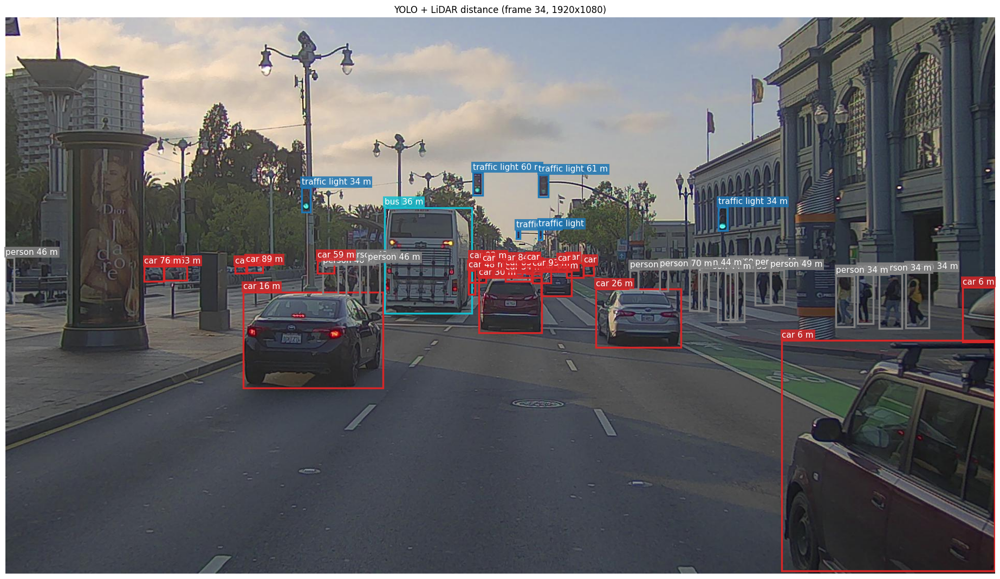


YOLO + LiDAR REPORT  (test frame 145)
YOLO objects : 23 car, 12 person
Total        : 35
 # class          conf  distance  lateral  dir    LiDAR pts  fusion-head
 1 car            0.95    12.5 m   +2.4 m  right       1987  agree
 2 person         0.65    38.4 m   +8.3 m  right         52  agree
 3 person         0.68    38.5 m   +9.1 m  right         33  agree
 4 person         0.70    38.8 m   +9.8 m  right         65  agree
 5 person         0.26    38.8 m   +9.6 m  right         26  agree
 6 car            0.89    41.3 m   +2.7 m  ahead        178  agree
 7 car            0.88    46.1 m   -0.7 m  ahead        121  agree
 8 person         0.22    48.1 m   +6.8 m  right         19  agree
 9 person         0.50    55.4 m   +9.3 m  right         36  agree
10 person         0.19    55.5 m   +9.7 m  right         19  agree
11 person         0.43    55.6 m  +10.1 m  right         46  agree
12 person         0.50    55.8 m  +11.0 m  right         49  agree
13 car            0.80    57.5 m 

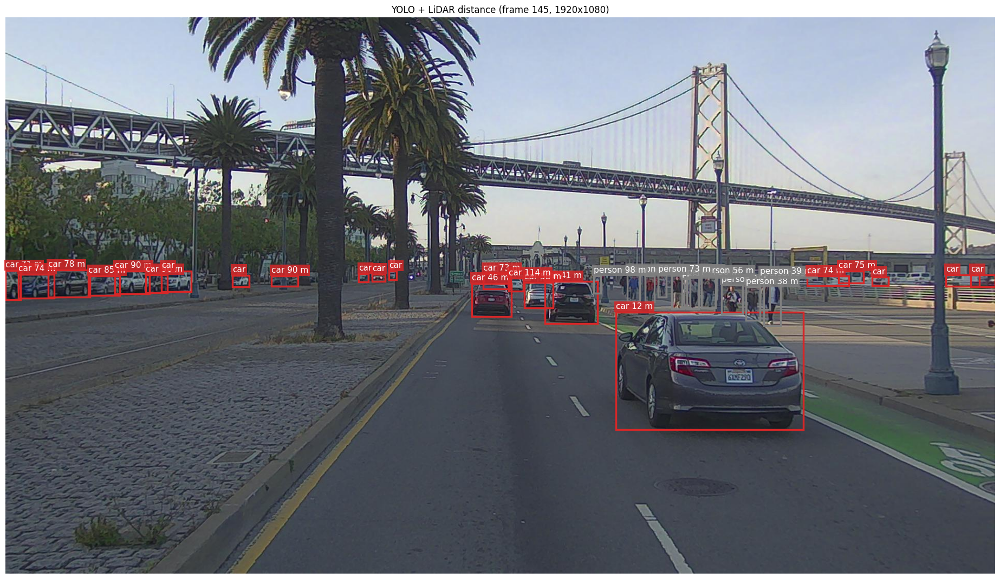


YOLO + LiDAR REPORT  (test frame 16)
YOLO objects : 21 car, 15 person, 1 bus, 5 traffic light
Total        : 42
 # class          conf  distance  lateral  dir    LiDAR pts  fusion-head
 1 car            0.85     5.8 m   -2.4 m  left           7  no match
 2 car            0.85     8.3 m   +2.4 m  right       4264  agree
 3 car            0.78     8.6 m   +2.8 m  right        544  agree
 4 person         0.30     8.6 m   +3.3 m  right         13  agree
 5 person         0.73     8.7 m   +3.3 m  right        219  agree
 6 car            0.83    17.7 m   +7.1 m  right        440  no match
 7 person         0.24    18.9 m   +7.7 m  right         14  agree
 8 car            0.91    22.5 m   -3.3 m  left         756  agree
 9 person         0.40    26.2 m  +11.0 m  right          7  no match
10 car            0.90    26.3 m   +3.5 m  ahead        442  agree
11 car            0.91    31.9 m   +0.6 m  ahead        291  agree
12 person         0.61    32.9 m  +14.2 m  right         16  no matc

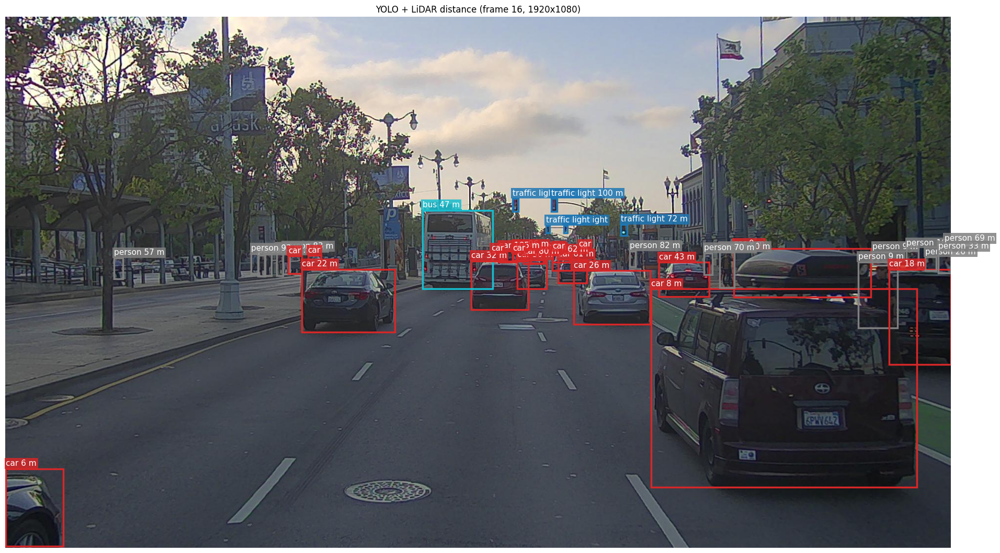


Saved yolo_lidar_reports.json and yolo_lidar_*.png in /kaggle/working
Saved: geosem_fsp_best.pt, loss_curve.png, alignment_*.png, *_input/_reconstructed PNGs, topview_*.png, scene_report_*.png, yolo_lidar_*.png in /kaggle/working


In [10]:
# ============================================================================
# 7. YOLO + LiDAR : what is it (YOLO), how far (LiDAR points inside the box)
# ============================================================================
def load_cam_points(lidar_path, w2c):
    df = pd.read_pickle(lidar_path)
    pts = df[["x", "y", "z"]].to_numpy(np.float64)
    pc = pts @ w2c[:3, :3].T + w2c[:3, 3]
    return pc[pc[:, 2] > 0.5]


def box_distance(pc, K, box, shrink=0.2, max_d=100.0):
    """Distance of a 2D box from the LiDAR points projected into its centre (nearest half, median)."""
    fx, fy, cx, cy = K
    x1, y1, x2, y2 = box
    w, h = x2 - x1, y2 - y1
    u = fx * pc[:, 0] / pc[:, 2] + cx
    v = fy * pc[:, 1] / pc[:, 2] + cy
    m = (u >= x1 + shrink * w) & (u <= x2 - shrink * w) & (v >= y1 + shrink * h) & (v <= y2 - shrink * h)
    sel = pc[m]
    if len(sel) < 3:
        return None
    d = np.linalg.norm(sel, axis=1)
    near = sel[d <= np.median(d)]
    dn = np.linalg.norm(near, axis=1)
    X, Z = float(np.median(near[:, 0])), float(np.median(near[:, 2]))
    if np.linalg.norm(near.mean(0)) > max_d:
        return None
    return dict(dist_m=float(np.median(dn)), x_m=X, z_m=Z, azimuth_deg=math.degrees(math.atan2(X, Z)), n_points=int(len(sel)))


@torch.no_grad()
def yolo_lidar_report(ds, n=3, seed=1):
    try:
        try:
            from ultralytics import YOLO
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
            from ultralytics import YOLO
        yolo = YOLO(YOLO_WEIGHTS)
    except Exception as e:
        print("\n[YOLO] Could not load YOLO (turn Internet ON in Kaggle settings, or set YOLO_WEIGHTS "
              f"to a .pt file in /kaggle/input). Reason: {e}")
        return

    model.eval()
    idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    cmap = plt.get_cmap("tab10")
    reports = []
    for i in idxs:
        smp = ds.samples[i]
        res = yolo.predict(smp["img"], conf=YOLO_CONF, imgsz=YOLO_IMGSZ, classes=YOLO_CLASSES, verbose=False)[0]
        names = res.names
        pc = load_cam_points(smp["lid"], smp["w2c"])

        head_objs = []
        if USE_DET:
            img_t, rv_t, _ = ds[i]
            out, _, _ = fwd(model, img_t[None].to(DEVICE), rv_t[None].to(DEVICE))
            head_objs = decode_objects(out, rv_t, smp["K"])

        objs = []
        for b, c, k in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.boxes.cls.cpu().numpy()):
            name = names[int(k)]
            info = box_distance(pc, smp["K"], b)
            o = dict(cls=name, conf=round(float(c), 2), box=[round(float(v)) for v in b],
                     dist_m=None if info is None else round(info["dist_m"], 1),
                     lateral_m=None if info is None else round(info["x_m"], 1),
                     azimuth_deg=None if info is None else round(info["azimuth_deg"], 1),
                     lidar_points=0 if info is None else info["n_points"], fusion_head="n/a")
            if info is not None:
                o["direction"] = "left" if info["azimuth_deg"] < -8 else "right" if info["azimuth_deg"] > 8 else "ahead"
                grp = YOLO_TO_DET.get(name)
                if USE_DET and grp is not None:
                    ok = any(h["cls"] == grp and abs(h["dist_m"] - info["dist_m"]) <= 5.0
                             and abs(h["azimuth_deg"] - info["azimuth_deg"]) <= 6.0 for h in head_objs)
                    o["fusion_head"] = "agree" if ok else "no match"
            else:
                o["direction"] = "-"
            objs.append(o)
        objs.sort(key=lambda o: (o["dist_m"] is None, o["dist_m"] or 0))

        counts = {}
        for o in objs: counts[o["cls"]] = counts.get(o["cls"], 0) + 1
        print("\n" + "=" * 90)
        print(f"YOLO + LiDAR REPORT  (test frame {i})")
        print("YOLO objects :", ", ".join(f"{v} {k}" for k, v in counts.items()) or "none")
        print(f"Total        : {len(objs)}")
        if objs:
            print(f"{'#':>2} {'class':<14}{'conf':>5}{'distance':>10}{'lateral':>9}  {'dir':<6}{'LiDAR pts':>10}  fusion-head")
            for k, o in enumerate(objs, 1):
                dd = "no LiDAR" if o["dist_m"] is None else f"{o['dist_m']:.1f} m"
                ll_ = "-" if o["lateral_m"] is None else f"{o['lateral_m']:+.1f} m"
                print(f"{k:>2} {o['cls']:<14}{o['conf']:>5.2f}{dd:>10}{ll_:>9}  {o['direction']:<6}{o['lidar_points']:>10}  {o['fusion_head']}")
            near = next((o for o in objs if o["dist_m"] is not None), None)
            if near:
                print(f"Closest      : {near['cls']} at {near['dist_m']:.1f} m ({near['direction']})")

        im = Image.open(smp["img"]).convert("RGB")
        fig, ax = plt.subplots(figsize=(19.2, 10.8)); ax.imshow(im); ax.axis("off")
        ax.set_title(f"YOLO + LiDAR distance (frame {i}, {im.size[0]}x{im.size[1]})")
        for o in objs:
            x1, y1, x2, y2 = o["box"]
            col = cmap(hash(o["cls"]) % 10)
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=2.5))
            lab = o["cls"] + ("" if o["dist_m"] is None else f" {o['dist_m']:.0f} m")
            ax.text(x1, max(y1 - 6, 0), lab, color="white", fontsize=11, bbox=dict(facecolor=col, alpha=0.85, pad=2, edgecolor="none"))
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"yolo_lidar_{i}.png"), dpi=100); plt.show()
        reports.append(dict(frame=i, counts=counts, objects=objs))

    with open(os.path.join(OUT_DIR, "yolo_lidar_reports.json"), "w") as f:
        json.dump(reports, f, indent=2)
    print("\nSaved yolo_lidar_reports.json and yolo_lidar_*.png in", OUT_DIR)


if USE_YOLO:
    yolo_lidar_report(test_ds, n=3)

print("Saved: geosem_fsp_best.pt, loss_curve.png, alignment_*.png, *_input/_reconstructed PNGs, topview_*.png, "
      "scene_report_*.png, yolo_lidar_*.png in", OUT_DIR)
